# Avance 4. Modelos alternativos

## Proyecto Integrador
### ThreatLLM: Clasificación de Ciberataques mediante Modelos de Lenguaje

**Equipo 55**

Integrantes

* Ada Jimena Vargas Aguirre — A01701619
* Edson Garduño Nolasco — A01795770
* Irving Alan García Zapata — A01796793


**Asesor**: Dr. Víctor Munguía




---

## Objetivos

3.3 Explorar una gama diversa de técnicas y enfoques con el fin de identificar el de mejor desempeño en el conjunto de datos en cuestión.

3.4 Encontrar la configuración óptima que maximiza el rendimiento del modelo en una tarea específica.

## Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Anthropic PBC. (2026). Claude (Sonnet 5.5) [Modelo de lenguaje grande].<br> https://claude.ai| Verificación y optimización de código. Generación de fragmentos de código. |Parte A - Celda 11, 12, 13,15 y 16 | Validar resultados entre iteraciones (que se respetara el uso de semilla) Cotejar resultados del baseline con el avance 3. |
| Anthropic. (2026). Claude Code (Claude Opus 5.5) [Modelo de lenguaje grande]. <br> https://claude.com/claude-code | Apoyo en el análisis del código de sensibilidad del CTS | Parte C | Ejecutar todas las celdas y verificar los resultados. Revisar a mano los cálculos de ejemplo (T1486, T1205) y la lógica de cada paso. |
Pendiente por definir (veáse nota)| Parte B | Revisión y corrección de errores de sintaxis. | Verificar el correcto funcionamiento.


### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| Ada | Parte A: Entrenamiento de modelos alternativos, análisis de resultados y redacción de hallazgos. |
| Edson | Parte B: Evaluación de la recuperación de técnicas MITRE Enterprise a partir de oraciones del reporte, comparando TF-IDF contra MiniLM. |
| Irving | Parte C: Construcción del código del análisis de sensibilidad del CTS y redacción de textos explicativos|

### Decisiones principales

<small> A continuación se documentan las tres decisiones que más influyeron en el avance, indicando qué alternativa se descartó.</small>

<small><b>Decisión 1:</b> TF-IDF de caracteres sobre embeddings MiniLM.</small>

- <small>Justificación:
TF-IDF mostró mejor rendimiento en LogReg (0.840 contra 0.802), Nearest Centroid (0.795 contra 0.746) y Ridge (0.837 contra 0.815).</small>
- <small>Alternativa descartada y motivo:
MiniLM no ganó en ningún algoritmo (empata en SVM y kNN, pierde en LogReg, Nearest Centroid y Ridge). Gemma y mpnet quedaron fuera por tiempo.</small>

<small><b>Decisión 2:</b> Afinar LogReg y Complement NB</small>

- <small>Justificación: La comparación permitió evaluar las ventajas y limitaciones de cada alternativa con criterios comunes (F1, F2, recall, entre otros). LogReg es la referencia del Av3 y es interpretable. Complement NB: tiene el mejor recall (0.932) y F2 (0.878) antes de afinar.
</small>
- <small>Alternativa descartada y motivo: Se descartó SVM RBF, ya que empató con el baseline en F1 (0.841 contra 0.840) pero entrena en ~6 a 7 s contra ~1 s, sin ventaja clara.</small>

<small><b>Decisión 3:</b> Elegir Complement NB sobre LogReg por recall y F2.</small>

- <small>Justificación: En test el recall es 0.961 contra 0.789 del baseline, y los falsos negativos bajan de 70 a 13.</small>
- <small>Alternativa descartada y motivo: LogReg, que tiene mejor precisión (0.84 contra 0.69) e interpretabilidad.
IMPORTANTE: Esta elección es condicional a la respuesta del cliente.</small>

----

- <small>Nota: Por motivos de salud del compañero, no nos fue posible obtener este dato de la Parte B. En cuanto se tenga, se actulizará la declaración.

Agradecemos su comprensión.

</small>
---

# Parte A | Exploración de modelos alternativos

En esta sección primero se convierte cada oración en un vector o *embedding* usando MiniLM en primera instancia, después se guardan en formato `.npy`; es decir, se calcula solo una vez para su uso posterior.

Acto seguido, se define la función `evaluar()`, con la cual se mide el desempeño de cada uno de los modelos probados. Para ello, se emplea validación cruzada de 5 pliegues en el conjunto train, se obtienen las métricas para el conjunto dev, así como el registro de tiempo de ejecución de cada modelo.

Luego se prueban **6 algoritmos distintos** (individuales, sin ensambles). En este caso se analizaron:
1. LogReg
2. Complement NB
3. SVM RBF
4. kNN
5. Árbol de decisión
6. MLP

Cada uno con dos representaciones cuando es posible:
* TF-IDF de caracteres
* Embeddings (NB solo con TF-IDF; MLP solo con embeddings).



Contexto adicional:

**Diferencia con el equipo anterior (Equipo 11)**

Usaron 8 algoritmos, una sola representación TF-IDF de palabras, evaluados en dev.

Aquí hay validación cruzada con desviación, dos representaciones, tiempos de entrenamiento y predicción, y después ajuste fino.


## 0. Configurar entorno

In [ ]:
#!pip -q install sentence-transformers          # Colab: quitamos el # la primera vez que se ejecutó
from pathlib import Path
import numpy as np, pandas as pd, time
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,fbeta_score, make_scorer
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

In [ ]:
# Definir rutas
DATA_DIR  = Path("data/ladder/sentence_classification")      # carpeta con train.csv, dev.csv, test.csv (separados por TAB)
KASPERSKY = Path("oraciones_kaspersky.csv")                  # id, tipo, texto (las 96 oraciones tienen tipo == "oracion")
EMB_NAME  = "minilm"                                         # "minilm" ; "mpnet"
OUT_DIR   = Path("."); SEED = 42

## 1. Cargar datos


In [ ]:
# Descomprimir carpeta ZIP con archivos necesarios para la ejecución del notebook
# La carpeta debe cargarse manualmente al entorno de Colab.
!unzip -q -o data.zip
!ls
!ls data

data		    emb_minilm_kaspersky.npy  oraciones_kaspersky.csv
data.zip	    emb_minilm_test.npy       sample_data
emb_minilm_dev.npy  emb_minilm_train.npy
attack_pattern	ladder	mitre  reports


In [ ]:
# Definir rutas/paths
tr = pd.read_csv(DATA_DIR / "train.csv", sep="\t"); dv = pd.read_csv(DATA_DIR / "dev.csv", sep="\t")
te = pd.read_csv(DATA_DIR / "test.csv",  sep="\t")
kas = pd.read_csv(KASPERSKY); kas = kas[kas["tipo"] == "oracion"].reset_index(drop=True)
print("train", tr.shape, "dev", dv.shape, "test", te.shape, "| oraciones reporte:", len(kas))
print("balance train:", tr.label.value_counts().to_dict())
ytr, ydv = tr.label.to_numpy(), dv.label.to_numpy()

train (2214, 2) dev (568, 2) test (662, 2) | oraciones reporte: 96
balance train: {1: 1107, 0: 1107}


## 2. Cálculo de embeddings

Primeramente, se definen las funciones para calcular y/o cargar los embeddings, según sea el caso.

Con esto presente, esta celda solo se ejecutó una vez.
Para ejecutar las celdas siguientes, se usaron los archivos `.npy` anexos.

Como primer experimento, se utilizó el modelo `all-MiniLM-L6-v2` por ser un codificador de oraciones y párrafos cortos, de peso ligero, propósito general y gratuito.

In [ ]:
# Función para crear los embeddings
def embeber(textos, nombre_modelo):
  from sentence_transformers import SentenceTransformer
  ids = {"minilm": "sentence-transformers/all-MiniLM-L6-v2", "mpnet": "sentence-transformers/all-mpnet-base-v2"}
  modelo = SentenceTransformer(ids[nombre_modelo])
  return modelo.encode(list(textos),batch_size = 64,normalize_embeddings = True, show_progress_bar=True)


# Función para cargar embeddings almacenados en .npy
def embeddings_cacheados(nombre):
  out, partes = {}, {"train": tr.text, "dev": dv.text, "test": te.text, "kaspersky": kas["texto"]}

  for k, t in partes.items():
        f = OUT_DIR / f"emb_{nombre}_{k}.npy"
        # Se carga si ya existe el archivo
        if f.exists():
          out[k] = np.load(f)
        # En caso de que no se tengan embeddings cargados, se crean y guardan
        else:
            t0 = time.time()
            out[k] = embeber(t, nombre)
            np.save(f, out[k])
            print(f"  {k}: {out[k].shape} guardado en {f.name} ({time.time()-t0:.0f}s)")
  return out

E = embeddings_cacheados(EMB_NAME)
print({k: v.shape for k, v in E.items()})


{'train': (2214, 384), 'dev': (568, 384), 'test': (662, 384), 'kaspersky': (96, 384)}


In [ ]:
# Comprobar normalización (escala 0-1)
np.linalg.norm(E["train"], axis=1)[:5]

array([0.99999994, 1.        , 1.        , 0.99999994, 1.        ],
      dtype=float32)

## 3. Evaluación inicial de modelos alternativos

Se definen las funciones necesarias para la medición de desempeño de los modelos y presentación de resultados.

In [ ]:
RESULTADOS = []

# Función para evaluar los modelos seleccionados
def evaluar(nombre, modelo, Xtr, ytr, Xdev, ydev, rep="", notas=""):
    """Misma medición para todos:
    - validación cruzada de 5 pliegues SOLO en train (métricas: F1, recall, precisión; media ± desviación)
    - entrenar en todo train (se mide el tiempo) y evaluar en dev (se mide el tiempo de predicción)
    `modelo` puede ser un Pipeline (TF-IDF + clasificador: el vectorizador se ajusta dentro de cada pliegue) o un clasificador
    sobre embeddings. Se guarda una fila en la lista RESULTADOS."""

    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    scoring = {"f1":"f1", "recall":"recall", "precision":"precision",
               "f2":make_scorer(fbeta_score, beta =2)}
    r = cross_validate(modelo, Xtr, ytr, cv=cv, scoring=scoring, n_jobs=1)
    t0 = time.perf_counter(); modelo.fit(Xtr, ytr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); p = modelo.predict(Xdev); t_pred = time.perf_counter() - t0

    fila = {"modelo": nombre, "representación": rep,
            "cv_f1": round(r["test_f1"].mean(), 3), "cv_f1_std": round(r["test_f1"].std(), 3),
            "cv_recall": round(r["test_recall"].mean(), 3), "cv_precision": round(r["test_precision"].mean(), 3),
            "cv_f2": round(r["test_f2"].mean(), 3), "cv_f2_std": round(r["test_f2"].std(), 3),
            "dev_acc": round(accuracy_score(ydev, p), 3), "dev_f1": round(f1_score(ydev, p), 3),
            "dev_recall": round(recall_score(ydev, p), 3), "dev_precision": round(precision_score(ydev, p), 3),
            "dev_f2": round(fbeta_score(ydev, p, beta=2), 3),
            "t_entrena_s": round(t_fit, 2), "t_predice_dev_s": round(t_pred, 3), "notas": notas}

    RESULTADOS.append(fila); return fila

# Función para convertir lista a dataframe y ordenar los valores
def tabla():
    return pd.DataFrame(RESULTADOS).sort_values("cv_f1", ascending=False).reset_index(drop=True)

Se agrega el baseline del avance previo para fines de comparación.

In [ ]:
# Baseline del Avance 3, NO cuenta entre los 6 modelos
baseline = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 6), sublinear_tf=True, min_df=1),
                         LogisticRegression(C=3, class_weight="balanced", solver="liblinear", max_iter=5000, random_state=SEED))

evaluar("REFERENCIA Av3: LogReg", baseline, tr.text, ytr, dv.text, ydv, rep="TF-IDF char (3,6)", notas="baseline Av3")

{'modelo': 'REFERENCIA Av3: LogReg',
 'representación': 'TF-IDF char (3,6)',
 'cv_f1': np.float64(0.84),
 'cv_f1_std': np.float64(0.009),
 'cv_recall': np.float64(0.844),
 'cv_precision': np.float64(0.837),
 'cv_f2': np.float64(0.842),
 'cv_f2_std': np.float64(0.017),
 'dev_acc': 0.815,
 'dev_f1': 0.821,
 'dev_recall': 0.849,
 'dev_precision': 0.795,
 'dev_f2': 0.837,
 't_entrena_s': 0.64,
 't_predice_dev_s': 0.126,
 'notas': 'baseline Av3'}

In [ ]:
#  8 ALGORITMOS diferentes (cada uno con 1 o 2 representaciones según sea el caso)
# Se incluye LogReg para referencia y comparación según la representación empleada (embeddings vs TF-IDF)

from sklearn.linear_model import RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.naive_bayes import GaussianNB, ComplementNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

def tfidf_char():   # TF-IDF de caracteres, igual que la baseline del Avance 3 (el vectorizador se ajusta dentro de cada pliegue)
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 6), sublinear_tf=True, min_df=1)

Xtr, Xdv = E["train"], E["dev"]
T_TXT, D_TXT = tr.text, dv.text
TF = "TF-IDF char (3,6)"

# Algoritmo 0: Regresión logística (lineal)
evaluar("0 LogReg", LogisticRegression(C=1, max_iter=2000, random_state=SEED), Xtr, ytr, Xdv, ydv, rep=EMB_NAME)
# (la fila de TF-IDF de este algoritmo es la REFERENCIA del Av3, ya medida arriba)

# Algoritmo 1: Gaussian Naive Bayes
evaluar("1 Gaussian NB", GaussianNB(), Xtr, ytr, Xdv, ydv,rep = EMB_NAME)

# Algoritmo 2: Complement Naive Bayes (probabilístico). Solo TF-IDF porque NB necesita valores no negativos
evaluar("2 Complement NB", make_pipeline(tfidf_char(), ComplementNB(alpha=0.5)), T_TXT, ytr, D_TXT, ydv, rep=TF,
        notas="alpha provisional")

# Algoritmo 3: SVM con kernel RBF (frontera no lineal)
evaluar("3 SVM RBF", SVC(C=1, kernel="rbf", gamma="scale", random_state=SEED), Xtr, ytr, Xdv, ydv, rep=EMB_NAME)
evaluar("3 SVM RBF", make_pipeline(tfidf_char(), SVC(C=1, kernel="rbf", gamma="scale", random_state=SEED)),
        T_TXT, ytr, D_TXT, ydv, rep=TF)

# Algoritmo 4: k vecinos más cercanos (basado en instancias)
evaluar("4 kNN (coseno)", KNeighborsClassifier(n_neighbors=15, metric="cosine", algorithm="brute"), Xtr, ytr, Xdv, ydv,
        rep=EMB_NAME, notas="k=15 provisional")
evaluar("4 kNN (coseno)", make_pipeline(tfidf_char(), KNeighborsClassifier(n_neighbors=15, metric="cosine", algorithm="brute")),
        T_TXT, ytr, D_TXT, ydv, rep=TF, notas="k=15 provisional")

# Algoritmo 5: Nearest Centroid/ Rocchio Classifier, se usa la métrica default (”euclidean”)
evaluar("5 Nearest Centroid",NearestCentroid(),Xtr,ytr,Xdv,ydv, rep = EMB_NAME)
evaluar("5 Nearest Centroid",make_pipeline(tfidf_char(),NearestCentroid()),T_TXT,ytr,D_TXT,ydv, rep = TF)

# Algoritmo 6: Ridge Classifier
evaluar("6 Ridge Classifier",RidgeClassifier(),Xtr,ytr,Xdv,ydv, rep = EMB_NAME)
evaluar("6 Ridge Classifier",make_pipeline(tfidf_char(),RidgeClassifier()),T_TXT,ytr,D_TXT,ydv, rep = TF)

# Algoritmo 7: Árbol de decisión (un solo árbol, NO es bosque)
evaluar("7 Árbol de decisión", DecisionTreeClassifier(max_depth=12, random_state=SEED), Xtr, ytr, Xdv, ydv, rep=EMB_NAME,
        notas="max_depth provisional")
evaluar("7 Árbol de decisión", make_pipeline(tfidf_char(), DecisionTreeClassifier(max_depth=12, random_state=SEED)),
        T_TXT, ytr, D_TXT, ydv, rep=TF, notas="max_depth provisional; puede tardar más")

# Algoritmo 8: Red neuronal MLP (una red pequeña; NO es ensamble). Solo embeddings (con 63k rasgos sería lenta) ---
evaluar("8 MLP", MLPClassifier(hidden_layer_sizes=(128,), alpha=1e-3, early_stopping=True, max_iter=300, random_state=SEED),
        Xtr, ytr, Xdv, ydv, rep=EMB_NAME, notas="128 neuronas provisional")



{'modelo': '8 MLP',
 'representación': 'minilm',
 'cv_f1': np.float64(0.802),
 'cv_f1_std': np.float64(0.011),
 'cv_recall': np.float64(0.848),
 'cv_precision': np.float64(0.761),
 'cv_f2': np.float64(0.829),
 'cv_f2_std': np.float64(0.015),
 'dev_acc': 0.761,
 'dev_f1': 0.755,
 'dev_recall': 0.739,
 'dev_precision': 0.772,
 'dev_f2': 0.746,
 't_entrena_s': 1.7,
 't_predice_dev_s': 0.002,
 'notas': '128 neuronas provisional'}

In [ ]:
T = tabla(); print(T.to_string(index=False))
T.to_csv(OUT_DIR / f"resultados_av4_bloque1_{EMB_NAME}.csv", index=False)

                modelo    representación  cv_f1  cv_f1_std  cv_recall  cv_precision  cv_f2  cv_f2_std  dev_acc  dev_f1  dev_recall  dev_precision  dev_f2  t_entrena_s  t_predice_dev_s                                   notas
             3 SVM RBF TF-IDF char (3,6)  0.841      0.010      0.836         0.847  0.838      0.018    0.813   0.817       0.835          0.801   0.828         7.06            1.425                                        
REFERENCIA Av3: LogReg TF-IDF char (3,6)  0.840      0.009      0.844         0.837  0.842      0.017    0.815   0.821       0.849          0.795   0.837         0.64            0.126                            baseline Av3
             3 SVM RBF            minilm  0.838      0.007      0.858         0.820  0.850      0.011    0.787   0.792       0.810          0.774   0.803         0.29            0.177                                        
    6 Ridge Classifier TF-IDF char (3,6)  0.837      0.013      0.839         0.836  0.838      0.023   

### Hallazgos de la comparativa

A modo de contexto, vale la pena señalar que la tabla anterior está ordenada por `cv_f1` (la cual fue seleccionada como métrica principal en la entrega previa), y que la desviación (`cv_f1_std`) permite identificar si una diferencia es ruido; es decir, si la diferencia observada entre las puntuaciones F1 de los modelos es pequeña respecto a la variabilidad de los resultados, no se tiene suficiente evidencia para asegurar que un modelo tenga un desempeño superior.

Con esto en mente, se describen los hallazgos:
1. **F1**

Los modelos que quedan prácticamente empatados en F1 son SVM RBF y LogReg, ambos con la representación de TF-IDF, porque sus medias (`cv_f1` = 0.841 y 0.840, respectivamente) difieren menos que su desviación estándar.

Asimismo, aunque no es concluyente, LogReg presenta un valor mayor en su desempeño en F1 sobre el conjunto dev (0.821 contra 0.817).

Por otro lado, existen otros modelos que también quedan empatados: SVM usando embeddings (0.838 ± 0.007) y Ridge con TF-IDF (0.837 ± 0.013). Sin embargo, ambos tienen un desempeño inferior que la primera pareja al ser evaluados sobre el conjunto dev (F1 de 0.792 y 0.807, respectivamente).

---

2. **¿Qué implica el empate para elegir?**

Dado que no es posible seleccionar un claro ganador por la métrica F1, este empate implica considerar otros valores obtenidos como criterios de selección: las métricas recall y F2, así como el tiempo de entrenamiento.


---
3. **Recall**

Al revisar el recall, los dos modelos que más lo favorecen son Complement NB con TF-IDF (`cv_recall` = 0.932) y kNN con embeddings (`cv_recall`= 0.921).

Esto a costa de su precisión tanto en validación cruzada como en su evaluación sobre dev.

Con un modelo así, puede significar que habría mayor cantidad de falsos positivos. En este caso, se tendría que sopesar si uno está dispuesto a tener más falsas alarmas, pero teniendo la mayor cantidad de verdaderos positivos.

---

4. **F2**

Ahora bien, al considerar F2, el orden cambia respecto a F1 y, nuevamente, Complement NB con TF-IDF (0.878 ± 0.016) y kNN con embeddings (0.866 ± 0.011) muestran los mejores desempeños en validación cruzada.

La diferencia entre ambos modelos es de 0.012, la cual es menor que la desviación (0.016), entonces no es posible decir que uno sea mejor que el otro.

Ahora, si se compara Complement NB (0.878) contra el baseline (0.842 ± 0.017), la diferencia es 0.036. Esta es aproximadamente el doble de la desviación (0.017) por lo que, probablemente, la mejora es consistente, no solo azar de la partición.

---
5. **Embeddings frente a TF-IDF**

Al comparar la misma técnica con ambas representaciones, se aprecia que en ningún algoritmo los embeddings superan a TF-IDF, sin embargo, en algunos empatan.

En los algoritmos LogReg (0.038), Nearest Centroid (0.049) y Ridge (0.022), la diferencia es mayor que las desviaciones.

En el caso de SVM RBF (0.003) y kNN (0.005) las diferencias son menores a la desviación así que están en empate.

En el caso del árbol de decisión (0.032), este queda en el límite, con desviaciones de 0.022 y 0.024.

También es importante mencionar que hay modelos que solo usaron una representación por la forma en que estos funcionan:
* Gaussian NB (embeddings) -> requiere matrices densas, TF-IDF es dispersa
* Complement NB (TF-IDF) -> necesita valores no negativos y los embeddings tienen negativos
* MLP (embeddings) -> se optó por embeddings porque usar 63,000 rasgos (TF-IDF) haría que fuera lento.

Por otro lado, a primer vistazo, los tiempos de entrenamiento disminuyen al usar los embeddings. No obstante, no son del todo comparables porque el tiempo para TF-IDF incluye construir el vectorizador dentro del pipeline, y el de embeddings no incluye calcularlos (se hizo una sola vez).

Es importante destacar que en kNN el tiempo de entrenamiento no es informativo, pues el modelo solo almacena datos. Su costo como tal está en el tiempo de predicción, y en la versión TF-IDF el tiempo de entrenamiento incluye el cálculo del vectorizador.


Con lo anterior presente, para el ajuste fino se eligen como dos modelos: LogReg + TF-IDF, y Complement NB + TF-IDF.

El primero por su desempeño en F1, su tiempo de entrenamiento (0.56 s contra 6.14 s de SVM TF-IDF), la interpretabilidad de los coeficientes y que su C = 3 es un valor heredado sin ajuste.

El segundo modelo se selecciona por su rendimiento ligeramente mayor en F2 y recall, en comparación con kNN. Además, su hiperparámetro principal (`alpha`) es sencillo de explorar. Se reconoce el compromiso que implica en F1 y precisión.

Los hiperparámetros (C y tipo de penalización en LogReg; alpha en Complement NB; y los parámetros de TF-IDF) no están afinados, así que se procede a realizar ajuste fino.

## 4. Ajuste fino (Fine Tuning)

Primero se define la configuración de la búsqueda de hiperparámetros.

In [ ]:
import time
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate
from scipy.stats import loguniform
from sklearn.metrics import make_scorer, fbeta_score

# Las mismas 5 pruebas (misma semilla = mismos cortes del train)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

# Las 4 métricas que se miden en cada intento
# F2 se arma con beta = 2, así pesa más el recall
scoring = {"f1": "f1", "recall": "recall", "precision": "precision",
           "f2": make_scorer(fbeta_score, beta=2)}

# Función para probar n_iter combinaciones al azar.
# Se queda con la mejor según 'metrica'
def buscar(pipe, espacio, n_iter=40, metrica = "f1"):
    t0 = time.perf_counter()  # cronómetro
    bs = RandomizedSearchCV(pipe, espacio, n_iter=n_iter, scoring=scoring,
                            refit=metrica, # la metrica con la que se elige al "ganador"
                            cv=cv, n_jobs=-1, random_state=SEED)

    bs.fit(tr.text, ytr)      # SOLO train
    i = bs.best_index_        # posición del intento ganador

    print(f"mejor cv_{metrica} = {bs.best_score_:.3f} ± {bs.cv_results_[f'std_test_{metrica}'][i]:.3f}"
          f" | {time.perf_counter()-t0:.0f} s | {bs.best_params_}")
    return bs

# Ajustes para el TF-IDF (es igual para ambos modelos)
tfidf_esp = {"tfidfvectorizer__ngram_range": [(2, 5), (3, 6), (3, 7), (4, 6)],  #largo de los n-gramas
             "tfidfvectorizer__min_df": [1, 2, 3],                              # mínimo de oraciones donde debe aparecer un n-grama
             "tfidfvectorizer__sublinear_tf": [True, False]}                    # suavizar repeticiones

# LogReg
# C = qué tan "suelto" es el modelo o qué tanta libertad se le da al modelo para ajustarse al train
# penalty = tipo de penalización
pipe_lr = make_pipeline(TfidfVectorizer(analyzer="char_wb"),
                        LogisticRegression(class_weight="balanced", solver="liblinear",
                                           max_iter=5000, random_state=SEED))
esp_lr = {**tfidf_esp, "logisticregression__C": loguniform(1e-2, 1e2),
          "logisticregression__penalty": ["l1", "l2"]}

# Complement NB
# alpha = suavizado
# norm = normalizar los pesos
pipe_nb = make_pipeline(TfidfVectorizer(analyzer="char_wb"), ComplementNB())
esp_nb = {**tfidf_esp, "complementnb__alpha": loguniform(1e-3, 10),
          "complementnb__norm": [True, False]}

# Correr la búsqueda (60 intentos cada una)
bs_lr = buscar(pipe_lr, esp_lr, n_iter = 60, metrica = "f1") # LogReg se elige por F1 (lo equilibrado)
bs_nb = buscar(pipe_nb, esp_nb, n_iter = 60, metrica = "f2") # CNB se elige por F2 (porque importa el recall)

mejor cv_f1 = 0.841 ± 0.006 | 153 s | {'logisticregression__C': np.float64(3.382387201936218), 'logisticregression__penalty': 'l2', 'tfidfvectorizer__min_df': 2, 'tfidfvectorizer__ngram_range': (3, 7), 'tfidfvectorizer__sublinear_tf': True}
mejor cv_f2 = 0.890 ± 0.009 | 156 s | {'complementnb__alpha': np.float64(0.11040511903162252), 'complementnb__norm': True, 'tfidfvectorizer__min_df': 2, 'tfidfvectorizer__ngram_range': (2, 5), 'tfidfvectorizer__sublinear_tf': True}


Ahora, para tener forma de comparar se define una función para construir la tabla de comparación: antes del ajuste fino vs después con ajuste aplicado.

In [ ]:
# Definir función para tabla comparativa
# Se compara antes vs después (en validación cruzada, solo train)

def medir(nombre, modelo):   # Es el ANTES
    # Corre la misma validación cruzada de siempre (mismos pliegues, mismas métricas)
    # Resume en 'promedio +- desviación'
    r = cross_validate(modelo, tr.text, ytr, cv=cv, scoring=scoring, n_jobs=-1)
    fila = {"modelo": nombre}
    for m in ["f1", "recall", "f2"]:
        # r["test_f1"] trae 5 números (uno por pliegue): sacamos promedio ± desviación
        fila[f"cv_{m}"] = f"{r['test_'+m].mean():.3f} ± {r['test_'+m].std():.3f}"
    return fila

def mejor_de(nombre, bs):   # Es el DESPUÉS
    # cv_results_ guarda los resultados de TODOS los intentos
    # best_index_ es la posición del ganador
    r = pd.DataFrame(bs.cv_results_).iloc[bs.best_index_]
    fila = {"modelo": nombre}
    for m in ["f1", "recall", "f2"]:
        fila[f"cv_{m}"] = f"{r['mean_test_'+m]:.3f} ± {r['std_test_'+m]:.3f}"
    return fila

# Construir e imprimir tabla comparativa
antes_despues = pd.DataFrame([
    medir("LogReg ANTES (baseline, C=3)", baseline),                                   # el baseline del Av3
    mejor_de("LogReg DESPUÉS", bs_lr),
    medir("Complement NB ANTES (alpha=0.5)", make_pipeline(tfidf_char(), ComplementNB(alpha=0.5))),
    mejor_de("Complement NB DESPUÉS", bs_nb)])
print(antes_despues.to_string(index=False))


                         modelo         cv_f1     cv_recall         cv_f2
   LogReg ANTES (baseline, C=3) 0.840 ± 0.009 0.844 ± 0.024 0.842 ± 0.017
                 LogReg DESPUÉS 0.841 ± 0.006 0.842 ± 0.022 0.841 ± 0.014
Complement NB ANTES (alpha=0.5) 0.809 ± 0.016 0.932 ± 0.017 0.878 ± 0.016
          Complement NB DESPUÉS 0.804 ± 0.011 0.958 ± 0.011 0.890 ± 0.009


In [ ]:
# Revisión en dev (una vez por modelo)
_ = evaluar("LogReg afinado", bs_lr.best_estimator_, tr.text, ytr, dv.text, ydv, rep=TF)
_ = evaluar("Complement NB afinado", bs_nb.best_estimator_, tr.text, ytr, dv.text, ydv, rep=TF)


In [ ]:
T = tabla()     # tabla completa de todos los modelos evaluados
T[T["modelo"].str.contains("afinado")][["modelo", "dev_f1", "dev_recall", "dev_precision", "dev_f2"]]

,modelo,dev_f1,dev_recall,dev_precision,dev_f2
1,LogReg afinado,0.816,0.838,0.796,0.829
7,Complement NB afinado,0.772,0.968,0.643,0.879


In [ ]:
# Tiempos
# Estos cambian un poco entre ejecuciones del cuaderno

for nombre, modelo in [("LogReg afinado", bs_lr.best_estimator_),
                       ("Complement NB afinado", bs_nb.best_estimator_)]:
    t0 = time.perf_counter()
    modelo.fit(tr.text, ytr)    # entrenar con train
    t_fit = time.perf_counter() - t0

    t0 = time.perf_counter()
    modelo.predict(dv.text)     # predecir dev
    t_pred = time.perf_counter() - t0

    print(f"{nombre}: entrenamiento {t_fit:.2f} s | predicción en dev {t_pred:.3f} s")

LogReg afinado: entrenamiento 1.01 s | predicción en dev 0.191 s
Complement NB afinado: entrenamiento 0.75 s | predicción en dev 0.160 s


In [ ]:
# Diagnósticos de la búsqueda

# a. Rango de resultados: ¿qué tanto cambia el score entre los 60 intentos?
for bs, m in [(bs_lr, "f1"), (bs_nb, "f2")]:
    c = pd.DataFrame(bs.cv_results_)[f"mean_test_{m}"]
    print(f"{m}: mínimo {c.min():.3f}, máximo {c.max():.3f}")

# b. ¿En qué intento apareció el mejor? ¿dónde se presenta la meseta?
for bs, m in [(bs_lr, "f1"), (bs_nb, "f2")]:
    c = pd.DataFrame(bs.cv_results_)[f"mean_test_{m}"]
    print(f"{m}: el mejor apareció en el intento {int(c.idxmax()) + 1} de {len(c)}"
          f" | intentos a menos de 0.005 del mejor: {(c >= c.max() - 0.005).sum()}")

# c. Para LogReg específicamente
# Se buscan los intentos con F1 = 0 (el modelo se "apagó" y predice solo una clase)
cr = pd.DataFrame(bs_lr.cv_results_)
print("intentos con F1 = 0:", (cr.mean_test_f1 == 0).sum())
cr[cr.mean_test_f1 == 0][["param_logisticregression__penalty", "param_logisticregression__C"]]


f1: mínimo 0.000, máximo 0.841
f2: mínimo 0.823, máximo 0.890
f1: el mejor apareció en el intento 51 de 60 | intentos a menos de 0.005 del mejor: 3
f2: el mejor apareció en el intento 41 de 60 | intentos a menos de 0.005 del mejor: 10
intentos con F1 = 0: 9


,param_logisticregression__penalty,param_logisticregression__C
18,l1,0.060804
24,l1,0.019778
31,l1,0.027013
37,l1,0.198326
38,l1,0.027555
49,l1,0.089238
51,l1,0.022970
52,l1,0.055728
59,l1,0.110488


### Hallazgos del ajuste fino


A continuación se describen los hallazgos reunidos para cada modelo.

**LogReg**

Se ajustaron `C`, la penalización y los parámetros de TF-IDF. En este caso, la mejor configuración encontrada fue:
  * `C` = 3.38 (heredado era 3)
  * penalización `l2`, la cual penaliza los pesos grandes (misma penalización del baseline).
  * `min_df` = 2, es la cantidad mínima de oraciones distintas en las que debe aparecer un "trozo" de letras para que el modelo lo considere.
  * n-gramas (3,7), es el tamaño de los trozos de letras con los que el modelo mira cada palabra.
  
Al comparar antes y después del ajuste fino (en validación cruzada) se observó que el cambio en `F1` fue pequeño (0.840 -> 0.841), y que el `recall` (0.844 -> 0.842) y `F2` (0.842 -> 0.841) prácticamente no cambiaron.

En otras palabras, todas las diferencias son aproximadamente 0.1 veces la desviación, lo que sugiere que no se puede determinar una mejora más allá del vaivén del propio modelo.

En dev (antes -> después):
  * `F1`: 0.821 -> 0.816
  * `recall`: 0.849 -> 0.838
  * Precisión: 0.795 -> 0.796
  * `F2`: 0.837 -> 0.829

En dev, no se observó una mejoría del modelo afinado frente al baseline.

Por otro lado, el valor de `C` es similar al heredado y está dentro del espacio de búsqueda explorado, lo que apunta a que el baseline estaba cerca de ser óptimo.

Además, en 9 de los 60 intentos se obtuvo `F1` = 0; todos usaron `l1` con `C` entre 0.02 y 0.20.

---
**Complement NB**

Los parámetros ajustados fueron:
* `alpha` = 0.110
* `norm` = True
* `min_df` = 2
* n-gramas (2,5)

Al comparar antes y después del ajuste fino, se notaron los siguientes cambios en las métricas durante la validación cruzada:

* `recall`: 0.932 -> 0.958
* `F2`: 0.878 -> 0.890
* `F1`: 0.809 -> 0.804
* Precisión: 0.714 -> 0.692

Mientras que en dev se tuvo:
  * `recall`: 0.940 -> 0.968
  * `F2`: 0.876 -> 0.879
  * `F1`: 0.795 -> 0.772
  * Precisión: 0.688 -> 0.643

Se observa que el `recall` alcanzó 1.5 veces su desviación, F2 se quedó cerca (0.8 veces).

Mientras que se ganó en recall y F2 (de forma marginal), se perdió precisión y `F1`.

El rango de `F2` en toda la búsqueda (los 60 intentos) fue de 0.823 a 0.890, lo que indica que el ajuste importa para este modelo (considerando que la diferencia entre el peor y mejor intento es de 0.067, y la desviación del modelo consigo mismo es de 0.009 a 0.016, por lo que la diferencia es al menos 4 veces la desviación).


## Modelo individual final

Se selecciona como modelo individual final a **Complement NB + TF-IDF**, esto porque se considera que las métricas con mayor peso para el negocio son `recall` y `F2`.

El costo (trade-off) está en la precisión (0.692 en CV, 0.643 en dev) y F1; donde aproximadamente 1 de cada 3 oraciones marcadas es falsa alarma. Aquí vale la pena recordar que un falso negativo (una amenaza real) se puede pasar por alto y no hay forma de recuperarla en etapas posteriores.

En cuanto a interpretabilidad, en LogReg cada trozo de letras (n-grama de caracteres) tiene un coeficiente con signo (positivo empuja hacia "ataque", negativo hacia "contexto"), lo cual es más directo al leer. En Complement NB cada trozo tiene un peso por clase, pero la lectura no es tan intuitiva porque los pesos son log-probabilidades. Para un analista de SOC, sería más fácil explicarle el modelo LogReg. Este es otro trade-off a tener en cuenta.

Respecto a tiempos, tanto LogReg (entrenamiento: 1.01 s, predicción en dev: 0.191 s) como Complement NB (entrenamiento: 0.75 s, predicción en dev: 0.160 s) son similares.

Se realiza esta selección para este avance, sin embargo está sujeta a la confirmación pendiente con el cliente; si este prefiere precisión sobre recall, LogReg es la alternativa.

In [ ]:
yte = te.label.to_numpy()   # etiquetas de test, igual que ytr y ydv

In [ ]:
# Evaluación final en test (una sola vez)

from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, fbeta_score, confusion_matrix

modelo_final = bs_nb.best_estimator_

pred = modelo_final.predict(te.text)

print(f"accuracy : {accuracy_score(yte, pred):.3f}")
print(f"F1       : {f1_score(yte, pred):.3f}")
print(f"recall   : {recall_score(yte, pred):.3f}")
print(f"precisión: {precision_score(yte, pred):.3f}")
print(f"F2       : {fbeta_score(yte, pred, beta=2):.3f}")

# Matriz de confusión
# filas = real (0 contexto, 1 ataque)
# columnas = predicho
print(confusion_matrix(yte, pred))

accuracy : 0.776
F1       : 0.811
recall   : 0.961
precisión: 0.702
F2       : 0.895
[[196 135]
 [ 13 318]]


### Hallazgo del modelo individual final sobre test

Se aprecia que el comportamiento del modelo descrito anteriormente en CV y dev se repite en test:
* `recall` alto (0.96)
* precisión baja (0.70)

| | Baseline Av3 (LogReg) | Complement NB afinado |
|---|---|---|
| Falsos negativos | 70 | **13** |
| Falsos positivos | 51 | 135 |
| Recall | 0.789 | **0.961** |
| F1 | 0.812 | 0.811 |
| Accuracy | 0.817 | 0.776 |

NOTA: valores sobre la misma partición de test, evaluada una sola vez.

Complement NB cumple los dos umbrales fijados en el Avance 3 (F1 ≥ 0.75 y recall ≥ 0.80), mientras que el baseline no cumple el de recall (0.789).

Si bien `accuracy` es de 0.776 (menor al baseline) y `F1` es de 0.811 (empatada al baseline), el modelo Complement NB gana en `recall`, pagando en precisión y `accuracy`. Esto es esperado, y se discutió anteriormente al darle prioridad a reducir falsos negativos.

`accuracy` disminuye porque el modelo reduce 57 falsos negativos (70 a 13), a costa de 84 falsos positivos adicionales. Además, esta métrica cuenta los dos errores como iguales, por ende, cualquier modelo que intercambie un tipo de error por otro, la hará bajar.

Con base en el contexto de negocio, el cambio permite compensar si un falso negativo cuesta más de ~1.5 falsos positivos (84 / 57 ≈ 1.47) y esto se somete a la confirmación del cliente.

Como hipótesis, se plantea que la etapa de similitud con MITRE podría filtrar las falsas alarmas. Por limitante de tiempo, esto queda como trabajo futuro.




# Parte B | Similitud

Esta sección retoma el hallazgo central de la Parte 2.4 del Avance 3: el único corpus de referencia técnica disponible (`attack-pattern-matching-gt`, 81 descripciones) es de malware **Mobile**, mientras que el reporte WIRTE/LitePower es **Enterprise** — repetir la Etapa 4 (oración → técnica, por similitud contra ese corpus) con embeddings MiniLM en vez de TF-IDF no resuelve ese desajuste de catálogo.

Además, para esta entrega no fue posible calcular `emb_minilm_attack_pattern.npy` (81×384): el entorno de cómputo usado no tenía instalado `sentence-transformers`/`torch` ni acceso a Hugging Face para descargar los pesos del modelo.

Como alternativa, B.3 compara las oraciones directamente contra el catálogo MITRE ATT&CK **Enterprise**, que es el catálogo correcto para dicho reporte.

En su lugar, esta sección usa un activo ya disponible y más rico que el ground truth a nivel de reporte: `anotacion_referencia.csv` incluye, para 24 de las 96 oraciones del reporte, la(s) técnica(s) Enterprise reales asignadas por el asesor (columna `ttps_gt`).

Esto permite responder, con evidencia cuantitativa nueva, la pregunta que la Parte 2.4 del Avance 3 dejó pendiente ("su evaluación contra las 18 técnicas del reporte queda pendiente"), a nivel de **oración-a-oración dentro del propio reporte**, usando los embeddings MiniLM ya calculados (`E["kaspersky"]`): ¿oraciones que de verdad corresponden a la misma técnica MITRE quedan semánticamente cerca entre sí en este espacio, más de lo que explicaría el azar?

In [ ]:
# B.0  Ground truth por oración (ttps_gt) + diccionario de las 18 técnicas
#      Enterprise del reporte (mismo usado en el Avance 3, sección 2.4)
anot = pd.read_csv("anotacion_referencia.csv")
kas_gt = kas.merge(anot[["id", "ttps_gt"]], on="id", how="left")
kas_gt["ttps_list"] = kas_gt["ttps_gt"].fillna("").apply(lambda s: [t.strip() for t in s.split(";") if t.strip()])

ttps_reporte = {
    "T1007": "System Service Discovery", "T1012": "Query Registry",
    "T1033": "System Owner/User Discovery", "T1041": "Exfiltration Over C2 Channel",
    "T1053": "Scheduled Task/Job", "T1059": "Command and Scripting Interpreter",
    "T1071": "Application Layer Protocol", "T1082": "System Information Discovery",
    "T1105": "Ingress Tool Transfer", "T1106": "Native API", "T1112": "Modify Registry",
    "T1113": "Screen Capture", "T1518": "Software Discovery",
    "T1547": "Boot or Logon Autostart Execution", "T1564": "Hide Artifacts",
    "T1574": "Hijack Execution Flow", "T1588": "Obtain Capabilities",
    "T1598": "Phishing for Information",
}

rng = np.random.default_rng(SEED)
labeled_mask = kas_gt["ttps_list"].apply(len) > 0
idx_labeled = np.where(labeled_mask.to_numpy())[0]
n_labeled = len(idx_labeled)

print(f"Oraciones del reporte con >=1 técnica anotada en ttps_gt: {n_labeled} de {len(kas_gt)}")
print(f"  (de estas, {(kas_gt['ttps_list'].apply(len) > 1)[idx_labeled].sum()} tienen más de una técnica)")
print(f"Técnicas del ground truth del reporte (18) presentes en ttps_gt: "
      f"{sorted(set(t for lst in kas_gt['ttps_list'] for t in lst))}")

emb_labeled = E["kaspersky"][idx_labeled]           # ya normalizados L2 (ver sección 2)
labels_labeled = kas_gt.loc[idx_labeled, "ttps_list"].tolist()

Oraciones del reporte con >=1 técnica anotada en ttps_gt: 24 de 96
  (de estas, 6 tienen más de una técnica)
Técnicas del ground truth del reporte (18) presentes en ttps_gt: ['T1007', 'T1012', 'T1033', 'T1041', 'T1053', 'T1059', 'T1071', 'T1082', 'T1105', 'T1112', 'T1113', 'T1518', 'T1547', 'T1564', 'T1574', 'T1598']


In [ ]:
# B.1  Similitud intra-técnica vs. una línea base por permutación
#      (¿las oraciones de la MISMA técnica quedan más cerca entre sí de lo
#      que explicaría el azar, en el espacio de embeddings MiniLM?)
S_kas = emb_labeled @ emb_labeled.T
np.fill_diagonal(S_kas, np.nan)

def similitud_promedio(idxs):
    sub = S_kas[np.ix_(idxs, idxs)]
    iu = np.triu_indices(len(idxs), k=1)
    return float(np.nanmean(sub[iu]))

pos_por_tecnica = {}
for pos, labs in enumerate(labels_labeled):
    for t in labs:
        pos_por_tecnica.setdefault(t, []).append(pos)

N_PERM = 5000
filas_b1, cache_null = [], {}
for t, nombre in ttps_reporte.items():
    miembros = pos_por_tecnica.get(t, [])
    n = len(miembros)
    if n < 2:
        filas_b1.append({"tecnica": t, "nombre": nombre, "n_oraciones": n,
                          "similitud_intra": np.nan, "pctl_vs_azar": np.nan, "p_valor": np.nan})
        continue
    obs = similitud_promedio(miembros)
    if n not in cache_null:
        nulls = np.array([similitud_promedio(rng.choice(n_labeled, size=n, replace=False)) for _ in range(N_PERM)])
        cache_null[n] = nulls
    nulls = cache_null[n]
    filas_b1.append({"tecnica": t, "nombre": nombre, "n_oraciones": n,
                      "similitud_intra": round(obs, 4),
                      "pctl_vs_azar": round(float((nulls <= obs).mean()) * 100, 1),
                      "p_valor": round(float((nulls >= obs).mean()), 4)})

tabla_b1 = pd.DataFrame(filas_b1)
fondo_global = similitud_promedio(np.arange(n_labeled))

print(f"Similitud promedio de fondo (todos los pares entre las {n_labeled} oraciones etiquetadas): {fondo_global:.4f}\n")
print(f"Similitud intra-técnica (MiniLM) vs. {N_PERM} muestras aleatorias del mismo tamaño:")
print(tabla_b1.sort_values("similitud_intra", ascending=False).to_string(index=False))

n_con_2_mas = tabla_b1["n_oraciones"].ge(2).sum()
n_sig = (tabla_b1["p_valor"] < 0.05).sum()
print(f"\nTécnicas con 2+ oraciones anotadas: {n_con_2_mas} de 18 "
      f"(las {18-n_con_2_mas} restantes no permiten medir similitud intra-grupo).")
print(f"De esas {n_con_2_mas}, {n_sig} tienen similitud intra-técnica significativamente mayor que el azar (p<0.05).")

Similitud promedio de fondo (todos los pares entre las 24 oraciones etiquetadas): 0.2600

Similitud intra-técnica (MiniLM) vs. 5000 muestras aleatorias del mismo tamaño:
tecnica                            nombre  n_oraciones  similitud_intra  pctl_vs_azar  p_valor
  T1547 Boot or Logon Autostart Execution            2           0.7406          99.2   0.0120
  T1112                   Modify Registry            2           0.7379          98.5   0.0180
  T1564                    Hide Artifacts            4           0.5313          99.6   0.0036
  T1598          Phishing for Information            2           0.4494          89.2   0.1116
  T1071        Application Layer Protocol            2           0.4072          83.5   0.1674
  T1041      Exfiltration Over C2 Channel            2           0.3926          80.4   0.1986
  T1059 Command and Scripting Interpreter            4           0.3901          93.2   0.0680
  T1033       System Owner/User Discovery            2           0.375

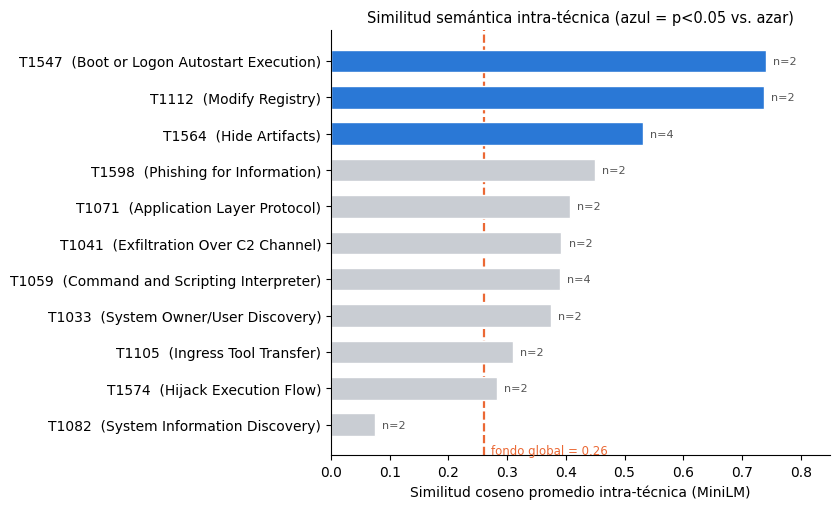

In [ ]:
import matplotlib.pyplot as plt

# Gráfica: similitud intra-técnica (solo n>=2), coloreada por significancia
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#C9CDD3"
t_plot = tabla_b1.dropna(subset=["similitud_intra"]).sort_values("similitud_intra").reset_index(drop=True)
colores = [AZUL if p < 0.05 else GRIS for p in t_plot["p_valor"]]
etiquetas = [f"{r.tecnica}  ({r.nombre})" for r in t_plot.itertuples()]

fig, ax = plt.subplots(figsize=(8.5, 5.2))
bars = ax.barh(etiquetas, t_plot["similitud_intra"], color=colores, edgecolor="white", height=0.62)
ax.axvline(fondo_global, color=NARANJA, linestyle="--", linewidth=1.6, zorder=0)
ax.text(fondo_global + 0.012, -0.7, f"fondo global = {fondo_global:.2f}", color=NARANJA, fontsize=8.5, va="center")
for bar, n in zip(bars, t_plot["n_oraciones"]):
    ax.text(bar.get_width() + 0.012, bar.get_y() + bar.get_height()/2, f"n={int(n)}", va="center", fontsize=8, color="#555")
ax.set_xlabel("Similitud coseno promedio intra-técnica (MiniLM)")
ax.set_title("Similitud semántica intra-técnica (azul = p<0.05 vs. azar)", fontsize=10.5)
ax.set_xlim(0, max(0.85, t_plot["similitud_intra"].max() + 0.08))
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

De las 18 técnicas del ground truth, solo 11 tienen 2 o más oraciones anotadas en el reporte (las otras 7 tienen 0 o 1, la misma limitación de "pocos datos por clase" ya documentada para `attack-pattern-matching-gt` en la Parte 2, aquí a menor escala). De esas 11, **3 (T1547, T1112, T1564)** tienen una similitud intra-técnica significativamente mayor que un grupo aleatorio del mismo tamaño (p<0.05); el resto muestra la misma tendencia (10 de 11 por encima del fondo global de 0.26) pero sin significancia individual, esperable con grupos de tamaño 2, donde el test de permutación tiene poca potencia estadística.

In [ ]:
# B.2  Recuperación por vecino más cercano (top-3, mismo K de la Etapa 4)
#      y prueba de permutación de ETIQUETAS como línea base de azar
K = 3
orden_vecinos = np.argsort(-np.nan_to_num(S_kas, nan=-1.0), axis=1)

def comparte_tecnica(labs_a, labs_b):
    return len(set(labs_a) & set(labs_b)) > 0

hit1_real = np.zeros(n_labeled, dtype=bool)
hit3_real = np.zeros(n_labeled, dtype=bool)
for i in range(n_labeled):
    vecinos = orden_vecinos[i, :K]
    hit1_real[i] = comparte_tecnica(labels_labeled[i], labels_labeled[vecinos[0]])
    hit3_real[i] = any(comparte_tecnica(labels_labeled[i], labels_labeled[v]) for v in vecinos)

prec_at_1 = hit1_real.mean()
hit_at_3 = hit3_real.mean()
print("Recuperación por vecino más cercano (coincide = comparte >=1 técnica con el vecino):")
print(f"  precision@1: {prec_at_1:.3f}  ({hit1_real.sum()}/{n_labeled})")
print(f"  hit@3:       {hit_at_3:.3f}  ({hit3_real.sum()}/{n_labeled})")

N_PERM_LABELS = 5000
idx_arr = np.arange(n_labeled)
perm_p1 = np.empty(N_PERM_LABELS)
perm_h3 = np.empty(N_PERM_LABELS)
for b in range(N_PERM_LABELS):
    perm = rng.permutation(idx_arr)
    labs_perm = [labels_labeled[p] for p in perm]
    h1 = np.zeros(n_labeled, dtype=bool)
    h3 = np.zeros(n_labeled, dtype=bool)
    for i in range(n_labeled):
        vecinos = orden_vecinos[i, :K]
        h1[i] = comparte_tecnica(labs_perm[i], labs_perm[vecinos[0]])
        h3[i] = any(comparte_tecnica(labs_perm[i], labs_perm[v]) for v in vecinos)
    perm_p1[b] = h1.mean()
    perm_h3[b] = h3.mean()

p_val_p1 = float((perm_p1 >= prec_at_1).mean())
p_val_h3 = float((perm_h3 >= hit_at_3).mean())
print(f"\nLínea base por azar (etiquetas barajadas, {N_PERM_LABELS} permutaciones):")
print(f"  precision@1 esperada: {perm_p1.mean():.3f} (std {perm_p1.std():.3f})  p={p_val_p1:.4f}")
print(f"  hit@3 esperado:       {perm_h3.mean():.3f} (std {perm_h3.std():.3f})  p={p_val_h3:.4f}")

Recuperación por vecino más cercano (coincide = comparte >=1 técnica con el vecino):
  precision@1: 0.500  (12/24)
  hit@3:       0.667  (16/24)

Línea base por azar (etiquetas barajadas, 5000 permutaciones):
  precision@1 esperada: 0.077 (std 0.063)  p=0.0000
  hit@3 esperado:       0.211 (std 0.097)  p=0.0002


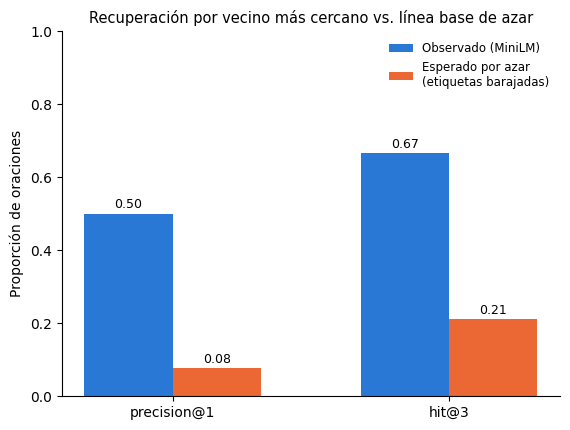

In [ ]:
import matplotlib.pyplot as plt

# Gráfica: recuperación observada vs. línea base de azar
x = np.arange(2); w = 0.32
fig, ax = plt.subplots(figsize=(5.8, 4.4))
b1 = ax.bar(x - w/2, [prec_at_1, hit_at_3], width=w, color=AZUL, label="Observado (MiniLM)")
b2 = ax.bar(x + w/2, [perm_p1.mean(), perm_h3.mean()], width=w, color=NARANJA, label="Esperado por azar\n(etiquetas barajadas)")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f"{b.get_height():.2f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["precision@1", "hit@3"])
ax.set_ylabel("Proporción de oraciones")
ax.set_ylim(0, 1.0)
ax.set_title("Recuperación por vecino más cercano vs. línea base de azar", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**Qué resuelven B.1 y B.2, y qué no.**

La prueba de recuperación por vecino más cercano es la evidencia más contundente: usando solo el ranking por similitud coseno de MiniLM (sin ningún clasificador ni etiqueta de técnica en el entrenamiento), el vecino más similar de una oración comparte su técnica real el 50 % de las veces (12/24), y al menos uno de los 3 vecinos más cercanos la comparte el 67 % de las veces (16/24) — frente a un 7.7 % y 21 % esperados por puro azar (misma frecuencia de técnicas, etiquetas barajadas; p<0.0001 y p=0.0002, 5000 permutaciones). Esto **sí responde**, con evidencia cuantitativa nueva, la pregunta que la Parte 2.4 del Avance 3 dejó abierta: la similitud semántica (al menos con MiniLM) captura señal real de coherencia por técnica en este reporte — no es ruido.

Lo que B.1 y B.2 **no** resuelven es vincular una oración con una técnica MITRE *fuera* del propio reporte: solo comparan oraciones contra oraciones del mismo reporte. Eso se aborda en B.3, contra el catálogo Enterprise. El corpus Mobile `attack-pattern-matching-gt` queda descartado como referencia para este reporte (desajuste de catálogo, Parte 2.4), por lo que ya no hace falta calcular sus embeddings.

## B.3 Oraciones vs. catálogo MITRE ATT&CK Enterprise

B.1 y B.2 compararon **oraciones contra oraciones**. Esta subsección compara cada oración del reporte contra el **catálogo de técnicas de MITRE ATT&CK Enterprise** (227 técnicas padre), que es el catálogo al que pertenece el ground truth de WIRTE/LitePower. Así se evita el desajuste Mobile/Enterprise de la Parte 2.4: el catálogo de referencia es del mismo tipo que las técnicas que se quieren recuperar (las 18 del reporte están en él).

**Diseño de la evaluación.**
- *Consultas*: las 24 oraciones con técnica anotada en `ttps_gt` (única forma de tener respuesta correcta por oración).
- *Candidatas*: las 227 técnicas Enterprise, representadas por `nombre + descripción` oficial de MITRE (archivo `mitre_enterprise_techniques.json`, extraído de `mitre-attack/attack-stix-data`, solo técnicas padre activas). `ttps_gt` usa IDs de técnica padre (p. ej. `T1574`), por lo que se evalúa a ese nivel.
- *Aciertos*: una oración acierta en el rango *k* si alguna de sus técnicas reales queda entre las *k* candidatas más similares (hit@k); también se reporta MRR y el rango mediano de la técnica correcta. En empates se usa el rango más pesimista.
- *Referencias*: (1) azar, con la fórmula exacta de un orden aleatorio sobre las candidatas; (2) **lista oráculo** de solo las 18 técnicas del reporte: no es realista (en la práctica no se conoce esa lista) y sirve como techo que separa el error de "no distinguir entre técnicas parecidas" del de "buscar entre 227".
- *Representaciones*: TF-IDF (mismo recuperador de la Etapa 4, ahora contra Enterprise) y MiniLM (mismos embeddings de oraciones de la sección 2; solo hay que embeber las 227 descripciones).

In [ ]:
# B.3.0  Catálogo MITRE ATT&CK Enterprise (técnicas padre) y consultas a evaluar
import json
cat = json.load(open("mitre_enterprise_techniques.json", encoding="utf-8"))
tec = cat["tecnicas"]
ids_cat = [t["id"] for t in tec]
nombres_cat = {t["id"]: t["nombre"] for t in tec}
textos_cat = [f'{t["nombre"]}. {t["descripcion"]}' for t in tec]

faltan = [t for t in ttps_reporte if t not in ids_cat]
print(f'Catálogo: {len(tec)} técnicas Enterprise (colección STIX v{cat["version_coleccion_stix"]})')
print(f"Técnicas del ground truth del reporte presentes en el catálogo: {len(ttps_reporte) - len(faltan)} de {len(ttps_reporte)}")

textos_oraciones = kas_gt.loc[idx_labeled, "texto"].astype(str).tolist()
verdad = labels_labeled          # técnicas reales (lista de IDs) por oración, ya definido en B.0
print(f"Oraciones a evaluar: {len(textos_oraciones)}")

Catálogo: 227 técnicas Enterprise (colección STIX v20.0)
Técnicas del ground truth del reporte presentes en el catálogo: 18 de 18
Oraciones a evaluar: 24


In [ ]:
# B.3.1  Métrica de recuperación (reutilizable para cualquier representación)
from math import comb

def evaluar_recuperacion(S, ids_candidatas, verdad, ks=(1, 3, 5, 10)):
    """S: similitudes (n_oraciones x n_candidatas). Devuelve (resumen, rangos).
    rango = posición de la mejor técnica real; en empates se cuenta el caso pesimista."""
    N = len(ids_candidatas)
    rangos, azar = [], {k: [] for k in ks}
    for i, reales in enumerate(verdad):
        col = [ids_candidatas.index(t) for t in reales if t in ids_candidatas]
        s_real = max(S[i, c] for c in col)
        rangos.append(int((S[i] >= s_real).sum()))
        for k in ks:
            azar[k].append(1 - comb(N - len(col), k) / comb(N, k))
    rangos = np.array(rangos)
    resumen = {f"hit@{k}": float((rangos <= k).mean()) for k in ks}
    resumen["MRR"] = float((1 / rangos).mean())
    resumen["rango_mediano"] = float(np.median(rangos))
    resumen.update({f"azar hit@{k}": float(np.mean(azar[k])) for k in ks})
    return resumen, rangos

In [ ]:
# B.3.2  TF-IDF: oraciones vs. catálogo Enterprise (el recuperador de la Etapa 4, ahora contra Enterprise)
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(lowercase=True, stop_words="english")
M_cat = vec.fit_transform(textos_cat)
M_sent = vec.transform(textos_oraciones)
S_tfidf = (M_sent @ M_cat.T).toarray()          # filas normalizadas L2 -> producto punto = coseno

idx_oraculo = [ids_cat.index(t) for t in ttps_reporte]
res_tfidf, rangos_tfidf = evaluar_recuperacion(S_tfidf, ids_cat, verdad)
res_tfidf_or, _ = evaluar_recuperacion(S_tfidf[:, idx_oraculo], list(ttps_reporte), verdad)

orden_metricas = ["hit@1", "hit@3", "hit@5", "hit@10", "MRR", "rango_mediano"]
tabla_tfidf = pd.DataFrame({
    "TF-IDF (227 candidatas)": [res_tfidf[m] for m in orden_metricas],
    "azar (227)": [res_tfidf.get(f"azar {m}", np.nan) for m in orden_metricas],
    "TF-IDF (oráculo, 18)": [res_tfidf_or[m] for m in orden_metricas],
    "azar (18)": [res_tfidf_or.get(f"azar {m}", np.nan) for m in orden_metricas],
}, index=orden_metricas).round(3)
print("Oraciones vs. catálogo Enterprise con TF-IDF (24 oraciones con técnica anotada):")
print(tabla_tfidf.to_string())

Oraciones vs. catálogo Enterprise con TF-IDF (24 oraciones con técnica anotada):
               TF-IDF (227 candidatas)  azar (227)  TF-IDF (oráculo, 18)  azar (18)
hit@1                            0.208       0.006                 0.583      0.072
hit@3                            0.500       0.017                 0.750      0.209
hit@5                            0.583       0.028                 0.875      0.338
hit@10                           0.708       0.056                 0.917      0.626
MRR                              0.367         NaN                 0.709        NaN
rango_mediano                    3.500         NaN                 1.000        NaN


In [ ]:
# B.3.3  Detalle por oración (TF-IDF): rango de la técnica real y técnica más similar
filas = []
for i, (txt, reales) in enumerate(zip(textos_oraciones, verdad)):
    j = int(np.argmax(S_tfidf[i]))
    filas.append({"oracion": kas_gt.loc[idx_labeled[i], "id"], "reales": ";".join(reales),
                  "rango_real": int(rangos_tfidf[i]),
                  "top1": f"{ids_cat[j]} {nombres_cat[ids_cat[j]]}", "sim_top1": round(float(S_tfidf[i, j]), 3)})
print(pd.DataFrame(filas).sort_values("rango_real").to_string(index=False))

oracion            reales  rango_real                                       top1  sim_top1
   K027             T1564           1                       T1564 Hide Artifacts     0.171
   K088       T1041;T1113           1                       T1113 Screen Capture     0.168
   K068             T1053           1                   T1053 Scheduled Task/Job     0.205
   K065 T1071;T1059;T1041           1         T1041 Exfiltration Over C2 Channel     0.169
   K087             T1082           1         T1082 System Information Discovery     0.096
   K053       T1059;T1105           2                     T1610 Deploy Container     0.221
   K086             T1012           2                      T1112 Modify Registry     0.254
   K039             T1574           3                   T1496 Resource Hijacking     0.137
   K041             T1112           3                T1574 Hijack Execution Flow     0.181
   K104             T1598           3    T1059 Command and Scripting Interpreter     0.187

**Lectura de los resultados con TF-IDF** (la comparación con MiniLM está más abajo, en las secciones B.3.4 a B.3.6).

Con 227 candidatas, TF-IDF pone la técnica real en el primer lugar para el 21 % de las oraciones (5/24) y entre las 3 primeras para el 50 % (12/24), contra 0.6 % y 1.7 % por azar. Es decir, ya con una representación léxica simple, comparar contra el catálogo Enterprise recupera señal real, algo que el corpus Mobile no podía dar por construcción (0 de 18 por ID). El rango mediano de la técnica correcta es 3.5 entre 227.

Con la lista oráculo de 18 el hit@1 sube a 58 %, así que una parte importante del error es confundir técnicas parecidas, y otra parte es buscar entre 227. El detalle por oración (B.3.3) muestra dónde falla: las oraciones de T1564 (Hide Artifacts) que describen el mecanismo concreto del dropper de Excel (hojas y columnas ocultas con fórmulas, VBA) quedan en los rangos 48, 123 y 227, y las de T1547 en 14 y 31 (la oración habla de un archivo `winrm.vbs` y claves de registro). El reporte describe una implementación específica y la descripción oficial describe la técnica en general, así que comparten poco vocabulario: es la limitación léxica del TF-IDF ya documentada. Es el caso donde se espera que los embeddings ayuden; B.3.4 a B.3.6 lo comprueban.

**Límites.** n = 24 oraciones y 16 técnicas distintas: los porcentajes tienen mucho margen de error, y las 31 oraciones de ataque sin `ttps_gt` no se pueden evaluar. La representación del catálogo (nombre + descripción de la técnica padre) es una elección; incluir nombres de subtécnicas o procedimientos de ejemplo es una variante pendiente.

In [ ]:
# B.3.4  MiniLM: embeber las 227 descripciones (se guardan en caché, igual que train/dev/test/kaspersky)
f_cat = OUT_DIR / f"emb_{EMB_NAME}_enterprise.npy"
if f_cat.exists():
    emb_cat = np.load(f_cat)
else:
    emb_cat = embeber(textos_cat, EMB_NAME)
    np.save(f_cat, emb_cat)
print("emb_cat:", emb_cat.shape, "| normas ~1:", np.allclose(np.linalg.norm(emb_cat, axis=1), 1, atol=1e-4))

S_mini = emb_labeled @ emb_cat.T                 # embeddings de las 24 oraciones (B.0) vs. catálogo
res_mini, rangos_mini = evaluar_recuperacion(S_mini, ids_cat, verdad)
res_mini_or, _ = evaluar_recuperacion(S_mini[:, idx_oraculo], list(ttps_reporte), verdad)

tabla_cmp = pd.DataFrame({
    "TF-IDF (227)": [res_tfidf[m] for m in orden_metricas],
    "MiniLM (227)": [res_mini[m] for m in orden_metricas],
    "azar (227)": [res_tfidf.get(f"azar {m}", np.nan) for m in orden_metricas],
    "TF-IDF (oráculo 18)": [res_tfidf_or[m] for m in orden_metricas],
    "MiniLM (oráculo 18)": [res_mini_or[m] for m in orden_metricas],
    "azar (18)": [res_tfidf_or.get(f"azar {m}", np.nan) for m in orden_metricas],
}, index=orden_metricas).round(3)
print("Comparación TF-IDF vs. MiniLM (oraciones vs. catálogo Enterprise):")
print(tabla_cmp.to_string())

emb_cat: (227, 384) | normas ~1: True
Comparación TF-IDF vs. MiniLM (oraciones vs. catálogo Enterprise):
               TF-IDF (227)  MiniLM (227)  azar (227)  TF-IDF (oráculo 18)  MiniLM (oráculo 18)  azar (18)
hit@1                 0.208         0.375       0.006                0.583                0.667      0.072
hit@3                 0.500         0.458       0.017                0.750                0.917      0.209
hit@5                 0.583         0.667       0.028                0.875                0.917      0.338
hit@10                0.708         0.792       0.056                0.917                1.000      0.626
MRR                   0.367         0.494         NaN                0.709                0.775        NaN
rango_mediano         3.500         4.000         NaN                1.000                1.000        NaN


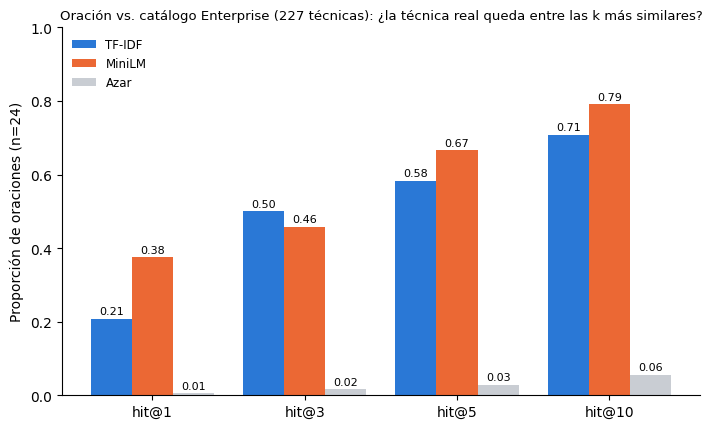

In [ ]:
# B.3.5  Gráfica: hit@k contra las 227 técnicas, TF-IDF vs. MiniLM vs. azar
import matplotlib.pyplot as plt
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#C9CDD3"
ks = [1, 3, 5, 10]
x = np.arange(len(ks)); w = 0.27
fig, ax = plt.subplots(figsize=(7.2, 4.4))
series = [("TF-IDF", [res_tfidf[f"hit@{k}"] for k in ks], AZUL),
          ("MiniLM", [res_mini[f"hit@{k}"] for k in ks], NARANJA),
          ("Azar", [res_tfidf[f"azar hit@{k}"] for k in ks], GRIS)]
for off, (nombre, vals, color) in zip([-w, 0, w], series):
    barras = ax.bar(x + off, vals, width=w, color=color, label=nombre)
    for b in barras:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.012, f"{b.get_height():.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f"hit@{k}" for k in ks])
ax.set_ylabel("Proporción de oraciones (n=24)"); ax.set_ylim(0, 1.0)
ax.set_title("Oración vs. catálogo Enterprise (227 técnicas): ¿la técnica real queda entre las k más similares?", fontsize=9.5)
ax.legend(frameon=False, fontsize=8.5)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
# B.3.6  ¿La diferencia TF-IDF vs. MiniLM es real o ruido? Bootstrap sobre las 24 oraciones (IC 95 %)
rng_b = np.random.default_rng(SEED)
n_o, B = len(rangos_tfidf), 10_000
muestras = rng_b.integers(0, n_o, size=(B, n_o))        # remuestreo de oraciones con reposición

def ic95(v):
    return np.percentile(v, [2.5, 97.5]).round(2)

filas = []
for k in (1, 3, 10):
    h_t = (rangos_tfidf[muestras] <= k).mean(axis=1)
    h_m = (rangos_mini[muestras] <= k).mean(axis=1)
    filas.append({"métrica": f"hit@{k}",
                  "TF-IDF": f"{np.mean(rangos_tfidf <= k):.2f} {ic95(h_t)}",
                  "MiniLM": f"{np.mean(rangos_mini <= k):.2f} {ic95(h_m)}",
                  "dif. MiniLM − TF-IDF": f"{np.mean(rangos_mini <= k) - np.mean(rangos_tfidf <= k):+.2f} {ic95(h_m - h_t)}"})
mrr_t = (1 / rangos_tfidf[muestras]).mean(axis=1); mrr_m = (1 / rangos_mini[muestras]).mean(axis=1)
filas.append({"métrica": "MRR",
              "TF-IDF": f"{np.mean(1 / rangos_tfidf):.2f} {ic95(mrr_t)}",
              "MiniLM": f"{np.mean(1 / rangos_mini):.2f} {ic95(mrr_m)}",
              "dif. MiniLM − TF-IDF": f"{np.mean(1 / rangos_mini) - np.mean(1 / rangos_tfidf):+.2f} {ic95(mrr_m - mrr_t)}"})
print(f"Bootstrap ({B} remuestreos de las {n_o} oraciones); entre corchetes, IC 95 %:")
print(pd.DataFrame(filas).to_string(index=False))
print(f"\nOraciones donde MiniLM mejora / empata / empeora el rango de la técnica real: "
      f"{int((rangos_mini < rangos_tfidf).sum())} / {int((rangos_mini == rangos_tfidf).sum())} / {int((rangos_mini > rangos_tfidf).sum())}")

detalle = pd.DataFrame({"oracion": kas_gt.loc[idx_labeled, "id"].to_numpy(), "reales": [";".join(v) for v in verdad],
                        "rango_tfidf": rangos_tfidf, "rango_minilm": rangos_mini}).sort_values("rango_minilm")
print("\nRango de la técnica real por oración (1 = primera):")
print(detalle.to_string(index=False))

Bootstrap (10000 remuestreos de las 24 oraciones); entre corchetes, IC 95 %:
métrica           TF-IDF           MiniLM dif. MiniLM − TF-IDF
  hit@1 0.21 [0.04 0.38] 0.38 [0.17 0.58]  +0.17 [-0.08  0.42]
  hit@3 0.50 [0.29 0.71] 0.46 [0.25 0.67]  -0.04 [-0.25  0.17]
 hit@10 0.71 [0.54 0.88] 0.79 [0.62 0.96]  +0.08 [-0.12  0.29]
    MRR 0.37 [0.23 0.51] 0.49 [0.33 0.66]  +0.13 [-0.06  0.3 ]

Oraciones donde MiniLM mejora / empata / empeora el rango de la técnica real: 16 / 3 / 5

Rango de la técnica real por oración (1 = primera):
oracion            reales  rango_tfidf  rango_minilm
   K023             T1059            6             1
   K041             T1112            3             1
   K053       T1059;T1105            2             1
   K039             T1574            3             1
   K040       T1574;T1112            3             1
   K088       T1041;T1113            1             1
   K067       T1518;T1033            3             1
   K065 T1071;T1059;T1041            1   

**Lectura comparativa TF-IDF vs. MiniLM (oraciones vs. catálogo Enterprise).**

*Ambas representaciones recuperan señal real.* Con 227 candidatas, la técnica correcta queda en el primer lugar para el 21 % (TF-IDF) y el 38 % (MiniLM) de las oraciones, contra 0.6 % por azar, y entre las 10 primeras para el 71 % y el 79 %, contra 5.6 %. Los límites inferiores de los intervalos de confianza de hit@1 (0.04 y 0.17) quedan por encima del azar. Con la lista oráculo de 18, MiniLM llega a hit@3 = 0.92 y hit@10 = 1.00; es un techo, no un desempeño realista.

*MiniLM tiende a ordenar mejor, pero la diferencia no es concluyente.* MiniLM mejora el rango de la técnica real en 16 de 24 oraciones, lo empata en 3 y lo empeora en 5; su MRR es 0.49 contra 0.37 y su hit@1 es 0.38 contra 0.21. Pero con n = 24 los intervalos se cruzan: la diferencia en hit@1 es +0.17 [−0.08, +0.42], en MRR +0.13 [−0.06, +0.30], y en hit@3 incluso es negativa (−0.04 [−0.25, +0.17]). No se puede afirmar que MiniLM supere a TF-IDF; sí que no lo empeora de forma apreciable y que ayuda donde TF-IDF era más débil.

*Dónde ayuda.* Las oraciones que describen un mecanismo concreto en vez de la técnica en general suben mucho de posición: K035 (T1547) pasa del rango 31 al 4, K003 (T1564) del 123 al 9, K026 (T1564) del 48 al 13 y K085 (T1033;T1007) del 17 al 2. Es la limitación léxica del TF-IDF que anticipamos, y es consistente con que los embeddings capturen significado más allá de las palabras compartidas.

*Dónde falla.* K104 (T1598) cae del rango 3 al 101 con MiniLM, K028 (T1564) sigue en 111 (con TF-IDF era 227) y K087 (T1082) y K068 (T1053) pasan del primer lugar al 7 y al 6. Una sola representación no cubre todos los casos, lo que motiva probar combinar ambas.

**Uso práctico y límites.** Con MiniLM la técnica correcta está entre las 10 candidatas más similares en ~79 % de las oraciones: una lista corta así puede alimentar un paso posterior (revisión del analista o un LLM que elija entre las 10), mejor que pedir una sola técnica. Límites: n = 24 oraciones y 16 técnicas distintas, evaluación a nivel de técnica padre, ground truth `ttps_gt` anotado manualmente (véase la revisión de etiquetas del Avance 3), y las 31 oraciones de ataque sin `ttps_gt` no se pueden evaluar. Pendiente: ampliar las oraciones anotadas, probar el catálogo con nombres de subtécnicas y combinar TF-IDF con MiniLM.

# Parte C | Análisis de sensibilidad para `Composite Threat Score`

El **Composite Threat Score (CTS)** es una calificación de 0 a 1 que el equipo anterior definió para decir qué tan peligrosa es cada técnica de ataque: entre más cerca de 1, más peligrosa. Sirve para que un analista sepa qué atender primero.

Para calcularla se combinan tres datos de cada técnica, cada uno con un porcentaje. El detalle es que esos porcentajes se eligieron "a ojo" y, además, el equipo anterior dejó **dos versiones distintas**:

| | Táctica más grave | Promedio de sus tácticas | Cuántas tácticas cubre |
|---|---|---|---|
| **Fórmula A** (Avance 2) | 50% | 30% | 20% |
| **Fórmula B** (Avance 5) | 65% | 35% | 0% |

**¿Importa cuál de las dos usar?** Para responderla, ordenamos las técnicas de la más a la menos peligrosa con cada fórmula y vemos si los órdenes se parecen.

Como tercera opción probamos el **Entropy Weight Method (EWM)**, que calcula los porcentajes a partir de los datos en lugar de ponerlos a ojo. Lo usamos solo para comparar, no como la respuesta correcta (más adelante explicamos por qué).

## C.1 Las técnicas y sus tres datos

**¿De dónde salen las técnicas?** Del catálogo oficial de MITRE ATT&CK **Enterprise**, versión 20.0, porque el cliente pidió empezar con Enterprise.

Algunas decisiones que tomamos:

- **Usamos solo las 227 técnicas principales** (por ejemplo `T1053`), sin sus subtécnicas (como `T1053.005`). Revisamos las 479 subtécnicas y todas tienen exactamente las mismas tácticas que su técnica principal, así que solo repetirían los mismos números.
- **Dejamos fuera las técnicas retiradas** (revocadas o deprecadas) por MITRE.
- **Dos tácticas nuevas:** en la versión 20, MITRE dividió *Defense Evasion* en *Stealth* y *Defense Impairment*. La tabla de pesos del equipo anterior no las tiene, así que a las dos les dimos el mismo peso que tenía *Defense Evasion* (0.55).

La siguiente celda descarga el catálogo (unos 55 MB, tarda pocos segundos) y prepara los pesos de cada táctica.

In [ ]:
# Librerías que usa esta parte
import json, urllib.request
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Catálogo oficial de MITRE ATT&CK Enterprise. Usamos una versión fija (20.0) para que el resultado siempre sea el mismo
RUTA_STIX = Path("data/mitre/enterprise-attack-20.0.json")
URL_STIX  = "https://raw.githubusercontent.com/mitre-attack/attack-stix-data/master/enterprise-attack/enterprise-attack-20.0.json"
if not RUTA_STIX.exists():
    RUTA_STIX.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL_STIX, RUTA_STIX)
objetos_mitre = json.load(open(RUTA_STIX))["objects"]

# Peso de cada táctica: la misma tabla del Avance 2 del equipo anterior
PESOS_TACTICA = {
    "Reconnaissance": 0.10, "Resource Development": 0.15, "Initial Access": 0.25, "Execution": 0.40,
    "Persistence": 0.45, "Privilege Escalation": 0.60, "Defense Evasion": 0.55, "Credential Access": 0.65,
    "Discovery": 0.35, "Lateral Movement": 0.50, "Collection": 0.70, "Command and Control": 0.55,
    "Exfiltration": 0.85, "Impact": 0.95,
}
# Las dos tácticas nuevas de la versión 20 heredan el peso de Defense Evasion
PESOS_TACTICA["Stealth"] = PESOS_TACTICA["Defense Impairment"] = PESOS_TACTICA["Defense Evasion"]

print("Objetos en el catálogo:", len(objetos_mitre))

Objetos en el catálogo: 26690


Ahora armamos la tabla. Para cada técnica calculamos sus **tres datos**:

| Columna | Qué es | Ejemplo |
|---|---|---|
| `max_w` | el peso de su táctica **más grave** | si tiene Impact (0.95) y Discovery (0.35), vale 0.95 |
| `mean_w` | el **promedio** de los pesos de sus tácticas | (0.95 + 0.35) / 2 = 0.65 |
| `versatilidad` | **cuántas tácticas** cubre, dividido entre 4 | 2 tácticas / 4 = 0.50 |

Dividimos entre 4 porque es el máximo de tácticas que tiene una técnica en Enterprise (*Valid Accounts*). Así, los tres datos quedan entre 0 y 1.

In [ ]:
# Traducir el nombre corto de cada táctica (ej. "credential-access") a su nombre completo
nombre_tactica = {o["x_mitre_shortname"]: o["name"] for o in objetos_mitre if o["type"] == "x-mitre-tactic"}

filas = []
for o in objetos_mitre:
    # Nos quedamos solo con técnicas principales y vigentes
    if o["type"] != "attack-pattern" or o.get("revoked") or o.get("x_mitre_deprecated") or o.get("x_mitre_is_subtechnique"):
        continue
    tid = next(r["external_id"] for r in o["external_references"] if r.get("source_name") == "mitre-attack")
    tacticas = [nombre_tactica[k["phase_name"]] for k in o["kill_chain_phases"] if k["kill_chain_name"] == "mitre-attack"]
    pesos = [PESOS_TACTICA[t] for t in tacticas]
    filas.append({"technique_id": tid, "nombre": o["name"], "tacticas": ", ".join(tacticas),
                  "max_w": max(pesos), "mean_w": np.mean(pesos), "n_tacticas": len(tacticas)})

tecnicas = pd.DataFrame(filas).sort_values("technique_id").reset_index(drop=True)
MAX_TACTICAS = tecnicas["n_tacticas"].max()
tecnicas["versatilidad"] = tecnicas["n_tacticas"] / MAX_TACTICAS

print(f"Técnicas principales: {len(tecnicas)}  |  Máximo de tácticas en una técnica: {MAX_TACTICAS}")
print("¿Cuántas técnicas tienen 1, 2, 3 o 4 tácticas?", tecnicas["n_tacticas"].value_counts().sort_index().to_dict())
tecnicas.head(10)

Técnicas principales: 227  |  Máximo de tácticas en una técnica: 4
¿Cuántas técnicas tienen 1, 2, 3 o 4 tácticas? {1: 201, 2: 21, 3: 4, 4: 1}


,technique_id,nombre,tacticas,max_w,mean_w,n_tacticas,versatilidad
0,T1001,Data Obfuscation,Command and Control,0.55,0.55,1,0.25
1,T1003,OS Credential Dumping,Credential Access,0.65,0.65,1,0.25
2,T1005,Data from Local System,Collection,0.70,0.70,1,0.25
3,T1006,Direct Volume Access,Stealth,0.55,0.55,1,0.25
4,T1007,System Service Discovery,Discovery,0.35,0.35,1,0.25
5,T1008,Fallback Channels,Command and Control,0.55,0.55,1,0.25
6,T1010,Application Window Discovery,Discovery,0.35,0.35,1,0.25
7,T1011,Exfiltration Over Other Network Medium,Exfiltration,0.85,0.85,1,0.25
8,T1012,Query Registry,Discovery,0.35,0.35,1,0.25
9,T1014,Rootkit,Stealth,0.55,0.55,1,0.25


Tenemos 227 técnicas, y hay un dato que explica casi todo lo que viene después: **201 de ellas (89%) tienen una sola táctica**. En esas técnicas, la táctica más grave y el promedio son el mismo número, y la versatilidad siempre vale 0.25. Solo 26 técnicas tienen 2 o más tácticas.

## C.2 Calificamos cada técnica con la fórmula A y con la B

Cada fórmula multiplica los tres datos por su porcentaje y los suma, igual que un promedio ponderado de calificaciones. Por ejemplo, para el ransomware (*Data Encrypted for Impact*, T1486), que solo tiene la táctica Impact (0.95):

- **A** = 0.50 × 0.95 + 0.30 × 0.95 + 0.20 × 0.25 = **0.81**
- **B** = 0.65 × 0.95 + 0.35 × 0.95 = **0.95**

Los números salen distintos porque cada fórmula califica a su manera. Ambas formulas indican: si es muy peligrosa. **Lo que importa no es el número exacto, sino el orden**: quién queda arriba de quién.

Con cada calificación hacemos dos cosas:
1. **Ordenar**: posición 1 = la más peligrosa. Si dos técnicas empatan, comparten posición.
2. **Poner una etiqueta**: Bajo (menos de 0.35), Medio (0.35 a 0.55), Alto (0.55 a 0.70) y Crítico (0.70 o más).

In [ ]:
# Porcentajes de cada fórmula, en el orden: [táctica más grave, promedio, versatilidad]
DATOS_CTS    = ["max_w", "mean_w", "versatilidad"]
FORMULAS_CTS = {"A": np.array([0.50, 0.30, 0.20]),
                "B": np.array([0.65, 0.35, 0.00])}

CORTES_CTS     = [0, 0.35, 0.55, 0.70, 1.0001]
ETIQUETAS_CTS  = ["Bajo", "Medio", "Alto", "Crítico"]

def calificar(nombre, porcentajes):
    # Calcula el CTS, la posición en el ranking y la etiqueta de cada técnica con una fórmula
    tecnicas[f"cts_{nombre}"] = tecnicas[DATOS_CTS].to_numpy() @ porcentajes
    tecnicas[f"pos_{nombre}"] = tecnicas[f"cts_{nombre}"].rank(ascending=False, method="min").astype(int)
    tecnicas[f"cat_{nombre}"] = pd.cut(tecnicas[f"cts_{nombre}"], bins=CORTES_CTS, labels=ETIQUETAS_CTS, include_lowest=True)

for nombre, porcentajes in FORMULAS_CTS.items():
    calificar(nombre, porcentajes)

# Tres ejemplos para ver cómo cambian las cosas de una fórmula a otra
ejemplos = ["T1486", "T1205", "T1001"]
tecnicas[tecnicas.technique_id.isin(ejemplos)][
    ["technique_id", "nombre", "tacticas", "cts_A", "pos_A", "cat_A", "cts_B", "pos_B", "cat_B"]].round(3)

,technique_id,nombre,tacticas,cts_A,pos_A,cat_A,cts_B,pos_B,cat_B
0,T1001,Data Obfuscation,Command and Control,0.49,81,Medio,0.550,72,Medio
87,T1205,Traffic Signaling,"Stealth, Persistence, Command and Control",0.58,46,Alto,0.538,124,Medio
104,T1486,Data Encrypted for Impact,Impact,0.81,1,Crítico,0.950,1,Crítico


**¿Qué vemos en los ejemplos?**

- **El ransomware (T1486)** queda en la posición 1 con las dos fórmulas. No se mueve.
- **Data Obfuscation (T1001)** tiene una sola táctica. Su calificación cambia, pero sigue igual de peligrosa respecto a las demás técnicas de una táctica. Sube un poco (de la posición 81 a la 72) solo porque algunas técnicas con varias tácticas bajaron y le dejaron lugar.
- **Traffic Signaling (T1205)** tiene 3 tácticas. La fórmula A le da puntos extra por eso y lo deja en la posición 46. La B no cuenta las tácticas y lo baja a la 124.

Es decir, **las fórmulas solo pueden "pelearse" en las técnicas que tienen varias tácticas**.

## C.3 ¿Las fórmulas A y B ordenan igual?

Para comparar las dos listas completas usamos tres medidas:

1. **Correlación de Spearman.** Mide qué tan parecidos son dos órdenes. Si coinciden en todo, da **1**; si su orden no tiene nada que ver, da **0**; si opinan exactamente lo contrario, da **-1**. Arriba de 0.9 se considera casi el mismo orden.
2. **Las más peligrosas.** Comparamos el 10% de arriba de cada lista (las primeras 23 posiciones), porque es lo que el analista atendería primero.
3. **Cambios de etiqueta.** Contamos cuántas técnicas cambian de Bajo, Medio, Alto o Crítico.

In [ ]:
TOP_CTS = round(0.10 * len(tecnicas))   # el 10% de arriba = 23 posiciones

def comparar_formulas(a, b):
    # Compara el orden que producen dos fórmulas
    top_a = set(tecnicas.loc[tecnicas[f"pos_{a}"] <= TOP_CTS, "technique_id"])
    top_b = set(tecnicas.loc[tecnicas[f"pos_{b}"] <= TOP_CTS, "technique_id"])
    return {"comparación": f"{a} vs {b}",
            "Spearman": round(spearmanr(tecnicas[f"cts_{a}"], tecnicas[f"cts_{b}"])[0], 3),
            "técnicas en el top 10% que coinciden": f"{len(top_a & top_b)} de {len(top_a | top_b)}",
            "técnicas que cambian de etiqueta": int((tecnicas[f"cat_{a}"] != tecnicas[f"cat_{b}"]).sum())}

pd.DataFrame([comparar_formulas("A", "B")])

,comparación,Spearman,técnicas en el top 10% que coinciden,técnicas que cambian de etiqueta
0,A vs B,0.979,25 de 25,5


In [ ]:
# ¿Cuántas técnicas caen en cada etiqueta con cada fórmula?
pd.DataFrame({f"Fórmula {k}": tecnicas[f"cat_{k}"].value_counts().reindex(ETIQUETAS_CTS) for k in FORMULAS_CTS})

,Fórmula A,Fórmula B
Bajo,59,59
Medio,98,97
Alto,45,46
Crítico,25,25


In [ ]:
# Las técnicas que cambian de etiqueta entre A y B
cambian = tecnicas[tecnicas.cat_A != tecnicas.cat_B]
cambian[["technique_id", "nombre", "tacticas", "cts_A", "cat_A", "cts_B", "cat_B"]].round(3).reset_index(drop=True)

,technique_id,nombre,tacticas,cts_A,cat_A,cts_B,cat_B
0,T1068,Exploitation for Privilege Escalation,Privilege Escalation,0.530,Medio,0.600,Alto
1,T1197,BITS Jobs,"Stealth, Persistence, Execution",0.565,Alto,0.521,Medio
2,T1205,Traffic Signaling,"Stealth, Persistence, Command and Control",0.580,Alto,0.538,Medio
3,T1548,Abuse Elevation Control Mechanism,Privilege Escalation,0.530,Medio,0.600,Alto
4,T1611,Escape to Host,Privilege Escalation,0.530,Medio,0.600,Alto


De las 5 técnicas que cambian, tres tienen una sola táctica (*Privilege Escalation*, con peso 0.60): A las baja a Medio y B las deja en Alto, que coincide con el peso de su táctica. Las otras dos (*BITS Jobs* y *Traffic Signaling*) tienen 3 tácticas, y A las sube a Alto solo por eso.

Las dos fórmulas ordenan las técnicas **casi igual**: Spearman de 0.979, el top 10% es exactamente el mismo (todas las técnicas de *Impact* y *Exfiltration*) y solo 5 de 227 técnicas cambian de etiqueta. Como hay empates, el top 10% tiene 25 técnicas en lugar de 23.

La razón es la que vimos en C.1: en las 201 técnicas con una sola táctica, A y B dan exactamente el mismo orden. Las diferencias solo aparecen en las 26 técnicas con varias tácticas, que revisamos aquí:

In [ ]:
varias_tacticas = tecnicas[tecnicas.n_tacticas > 1].sort_values("pos_A")
varias_tacticas[["technique_id", "nombre", "tacticas", "n_tacticas", "pos_A", "pos_B", "cat_A", "cat_B"]].reset_index(drop=True)

,technique_id,nombre,tacticas,n_tacticas,pos_A,pos_B,cat_A,cat_B
0,T1056,Input Capture,"Collection, Credential Access",2,26,41,Alto,Alto
1,T1557,Adversary-in-the-Middle,"Credential Access, Collection",2,26,41,Alto,Alto
2,T1556,Modify Authentication Process,"Defense Impairment, Persistence, Credential Ac...",3,28,57,Alto,Alto
3,T1078,Valid Accounts,"Stealth, Persistence, Privilege Escalation, In...",4,29,71,Alto,Alto
4,T1053,Scheduled Task/Job,"Execution, Persistence, Privilege Escalation",3,45,70,Alto,Alto
5,T1205,Traffic Signaling,"Stealth, Persistence, Command and Control",3,46,124,Alto,Medio
6,T1040,Network Sniffing,"Credential Access, Discovery",2,47,61,Alto,Alto
7,T1055,Process Injection,"Stealth, Privilege Escalation",2,48,62,Alto,Alto
8,T1134,Access Token Manipulation,"Stealth, Privilege Escalation",2,48,62,Alto,Alto
9,T1484,Domain or Tenant Policy Modification,"Defense Impairment, Privilege Escalation",2,48,62,Alto,Alto


La mayoría de estas técnicas bajan de posición con la fórmula B, porque B no premia cubrir varias tácticas y, además, el promedio "jala hacia abajo" cuando una de sus tácticas pesa poco.

Elegir entre A y B se reduce a una pregunta de criterio: **¿una técnica que sirve en varias etapas del ataque es más peligrosa por eso?** Nuestra respuesta es que no necesariamente: el número de tácticas describe cómo MITRE clasifica la técnica, no el daño que causa. Por eso nos inclinamos por B (lo explicamos en C.6).

## C.4 Una tercera opción: el Entropy Weight Method (EWM)

EWM calcula los porcentajes **a partir de los datos**. Su idea es darle más peso a la columna donde las técnicas son **más diferentes entre sí**, porque es la que más ayuda a separarlas. Por eso solo la usamos como comparación.

Los pasos son estos:
1. **Poner las columnas en la misma escala**, de 0 a 1 (el valor más bajo se vuelve 0 y el más alto, 1).
2. **Medir la entropía** de cada columna: qué tan parejos están sus valores. Muy parejos = la columna no distingue = poco peso.
3. **Repartir el peso**: las columnas menos parejas se llevan más porcentaje.

El paso 1 es una decisión nuestra. Por eso también probamos una versión **sin cambiar la escala**, para ver si EWM depende de esa decisión.

In [ ]:
def pesos_ewm(datos, cambiar_escala=True):
    # Entropy Weight Method: devuelve el porcentaje que le toca a cada columna
    if cambiar_escala:
        datos = (datos - datos.min(0)) / (datos.max(0) - datos.min(0))   # paso 1: escala de 0 a 1
    p = datos / datos.sum(0)                                             # proporción de cada técnica en la columna
    with np.errstate(divide="ignore", invalid="ignore"):
        p_log_p = np.where(p > 0, p * np.log(p), 0.0)
    entropia = -p_log_p.sum(0) / np.log(len(datos))                      # paso 2: 1 = muy parejo, 0 = muy desigual
    diversidad = 1 - entropia
    return diversidad / diversidad.sum()                                 # paso 3: repartir el 100%

datos_cts = tecnicas[DATOS_CTS].to_numpy()
FORMULAS_CTS["EWM"] = pesos_ewm(datos_cts)
FORMULAS_CTS["EWM sin escala"] = pesos_ewm(datos_cts, cambiar_escala=False)
for nombre in ["EWM", "EWM sin escala"]:
    calificar(nombre, FORMULAS_CTS[nombre])

# Porcentaje que le da cada fórmula a cada dato
(pd.DataFrame(FORMULAS_CTS, index=["Táctica más grave", "Promedio", "Cuántas tácticas"]) * 100).round(0).astype(int).astype(str) + "%"

,A,B,EWM,EWM sin escala
Táctica más grave,50%,65%,6%,38%
Promedio,30%,35%,6%,39%
Cuántas tácticas,20%,0%,88%,23%


EWM le da **88% del peso a "cuántas tácticas"** y casi ignora qué tan grave es la técnica. Distinguir no es lo mismo que importar.

Orden de las técnicas:

In [ ]:
pd.DataFrame([comparar_formulas(a, b) for a, b in
              [("A", "B"), ("A", "EWM"), ("B", "EWM"), ("A", "EWM sin escala"), ("B", "EWM sin escala")]])

,comparación,Spearman,técnicas en el top 10% que coinciden,técnicas que cambian de etiqueta
0,A vs B,0.979,25 de 25,5
1,A vs EWM,0.938,0 de 48,158
2,B vs EWM,0.875,0 de 48,158
3,A vs EWM sin escala,0.998,25 de 25,5
4,B vs EWM sin escala,0.980,25 de 25,10


In [ ]:
# Dos casos que muestran el problema de EWM
tecnicas[tecnicas.technique_id.isin(["T1486", "T1078"])][
    ["technique_id", "nombre", "n_tacticas", "pos_A", "cat_A", "pos_B", "cat_B", "pos_EWM", "cat_EWM"]].reset_index(drop=True)

,technique_id,nombre,n_tacticas,pos_A,cat_A,pos_B,cat_B,pos_EWM,cat_EWM
0,T1078,Valid Accounts,4,29,Alto,71,Alto,1,Crítico
1,T1486,Data Encrypted for Impact,1,1,Crítico,1,Crítico,27,Bajo


In [ ]:
# ¿Cuántas técnicas caen en cada etiqueta con cada fórmula?
pd.DataFrame({k: tecnicas[f"cat_{k}"].value_counts().reindex(ETIQUETAS_CTS) for k in FORMULAS_CTS})

,A,B,EWM,EWM sin escala
Bajo,59,59,201,59
Medio,98,97,21,103
Alto,45,46,0,40
Crítico,25,25,5,25


Con EWM, el ransomware (T1486) pasa de **Crítico en la posición 1** a **Bajo en la posición 27**, mientras que *Valid Accounts* (T1078), por tener 4 tácticas, se va al primer lugar. Además, 201 de las 227 técnicas quedan como "Bajo" y **ninguna** de las más peligrosas coincide con A ni con B. Para un analista de seguridad, este orden no tiene sentido.

La gráfica resume todo. Cada punto es una técnica: si queda sobre la línea diagonal, tiene la misma posición con las dos fórmulas. Los rombos azules son las técnicas con varias tácticas.

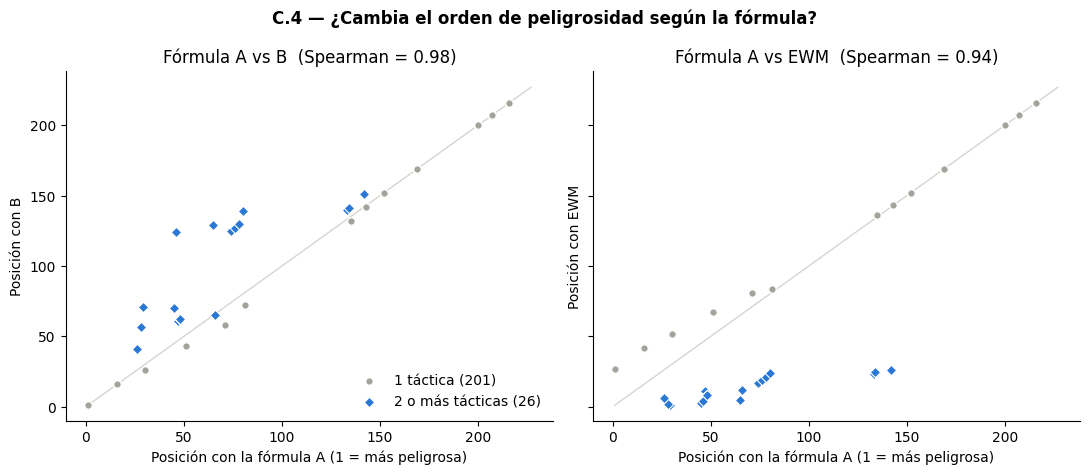

In [ ]:
GRIS, AZUL = "#a3a39b", "#2a78d6"
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
for eje, otra in zip(ejes, ["B", "EWM"]):
    for varias, color, marca, etiqueta in [(False, GRIS, "o", "1 táctica (201)"), (True, AZUL, "D", "2 o más tácticas (26)")]:
        grupo = tecnicas[(tecnicas.n_tacticas > 1) == varias]
        eje.scatter(grupo.pos_A, grupo[f"pos_{otra}"], s=28, c=color, marker=marca, edgecolors="white", linewidths=0.8, label=etiqueta)
    eje.plot([1, len(tecnicas)], [1, len(tecnicas)], color="#d6d5cf", lw=1, zorder=0)
    rho = spearmanr(tecnicas.cts_A, tecnicas[f"cts_{otra}"])[0]
    eje.set(title=f"Fórmula A vs {otra}  (Spearman = {rho:.2f})",
            xlabel="Posición con la fórmula A (1 = más peligrosa)", ylabel=f"Posición con {otra}")
    eje.spines[["top", "right"]].set_visible(False)
ejes[0].legend(frameon=False, loc="lower right")
plt.suptitle("C.4 — ¿Cambia el orden de peligrosidad según la fórmula?", fontweight="bold")
plt.tight_layout(); plt.show()

A la izquierda (A vs B), los puntos grises quedan sobre la diagonal o muy cerca, y solo se separan los rombos azules. A la derecha (A vs EWM), los rombos azules se van hasta abajo (EWM los pone entre los más peligrosos) y los puntos grises se despegan de la diagonal.

## C.5 ¿Y las técnicas del reporte de WIRTE?

Revisamos cómo quedan las 18 técnicas del reporte con cada fórmula:

In [ ]:
TECNICAS_REPORTE = ["T1007", "T1012", "T1033", "T1041", "T1053", "T1059", "T1071", "T1082", "T1105",
                    "T1106", "T1112", "T1113", "T1518", "T1547", "T1564", "T1574", "T1588", "T1598"]
(tecnicas[tecnicas.technique_id.isin(TECNICAS_REPORTE)].sort_values("pos_A")
 [["technique_id", "nombre", "tacticas", "pos_A", "cat_A", "pos_B", "cat_B", "pos_EWM", "cat_EWM"]].reset_index(drop=True))

,technique_id,nombre,tacticas,pos_A,cat_A,pos_B,cat_B,pos_EWM,cat_EWM
0,T1041,Exfiltration Over C2 Channel,Exfiltration,16,Crítico,16,Crítico,42,Bajo
1,T1113,Screen Capture,Collection,30,Alto,26,Alto,52,Bajo
2,T1053,Scheduled Task/Job,"Execution, Persistence, Privilege Escalation",45,Alto,70,Alto,3,Crítico
3,T1547,Boot or Logon Autostart Execution,"Persistence, Privilege Escalation",66,Alto,65,Alto,12,Medio
4,T1112,Modify Registry,"Defense Impairment, Persistence",74,Medio,125,Medio,17,Medio
5,T1574,Hijack Execution Flow,"Stealth, Execution",76,Medio,127,Medio,19,Medio
6,T1071,Application Layer Protocol,Command and Control,81,Medio,72,Medio,84,Bajo
7,T1564,Hide Artifacts,Stealth,81,Medio,72,Medio,84,Bajo
8,T1105,Ingress Tool Transfer,Command and Control,81,Medio,72,Medio,84,Bajo
9,T1059,Command and Scripting Interpreter,Execution,152,Medio,152,Medio,152,Bajo


Con A y B, las 18 técnicas del reporte conservan la misma etiqueta. La más grave es *Exfiltration Over C2 Channel* (Crítico), y las de exploración (*Discovery*) quedan como Bajo. Las que más se mueven de posición son, otra vez, las que tienen varias tácticas: *Scheduled Task/Job* (de la 45 a la 70), *Modify Registry* (de la 74 a la 125) y *Hijack Execution Flow* (de la 76 a la 127). Con EWM, en cambio, *Exfiltration Over C2 Channel* pasa a Bajo y *Scheduled Task/Job* a Crítico.

## C.6 Conclusiones

**1. Usar la fórmula A o la B casi no cambia nada.** Las dos ordenan las 227 técnicas casi igual (Spearman de 0.98), coinciden en las más peligrosas y solo 5 técnicas cambian de etiqueta. Esto pasa porque 9 de cada 10 técnicas tienen una sola táctica, y ahí las dos fórmulas dan el mismo orden. La única diferencia está en las 26 técnicas con varias tácticas: A las sube y B las baja.

**2. EWM no sirve como reemplazo.** En su versión estándar le da 88% del peso a "cuántas tácticas", porque es la columna que más distingue, no la más importante. El resultado deja al ransomware como "Bajo", lo cual no tiene sentido. Además, si se aplica sin cambiar la escala, da casi lo mismo que la fórmula A. Así que EWM tampoco es tan objetivo como parece: depende de cómo se use.

**3. ¿Por qué nos quedamos con la fórmula B?** Como A y B dan casi el mismo orden, la elección no cambia mucho los resultados. Aun así, B tiene ventajas:

- **No premia algo que no mide peligro.** Que una técnica aparezca en varias tácticas depende de cómo MITRE la clasifica, no de cuánto daño causa. Por ejemplo, *Valid Accounts* aparece en 4 tácticas porque los atacantes usan cuentas válidas en varias etapas del ataque, pero eso no la hace más grave que el ransomware. La fórmula A le da puntos extra por eso; la B no.
- **Es más fácil de explicar.** En el 89% de las técnicas (las de una sola táctica), la calificación de B es exactamente el peso de su táctica: Impact vale 0.95 y Discovery 0.35. Con A, ese peso se "encoge" y algunas técnicas cambian de etiqueta sin una razón clara. Por ejemplo, *Exploitation for Privilege Escalation* (T1068) tiene una sola táctica de peso 0.60 (Alto), pero A la deja como Medio (0.53). B la deja como Alto.
- **Evita la variable que más distorsiona el orden.** Con EWM vimos qué pasa cuando "cuántas tácticas" pesa mucho: el ransomware termina como Bajo. Con el 20% de la fórmula A no se llega a ese extremo, pero B evita el riesgo desde el inicio.